# IMDB Movie Review Sentiment Analysis Using Recurrent Neural Networks
* This project focuses on building a deep learning-based sentiment analysis system using the IMDB Movie Reviews dataset. 
* The objective is to classify movie reviews as positive or negative using Artificial Neural Networks (ANN), Simple Recurrent Neural Networks (SimpleRNN), Long Short-Term Memory (LSTM), Stacked LSTM, and Gated Recurrent Units (GRU).

## Download dataset using KaggleHub

In [1]:
import kagglehub

path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

print("Dataset downloaded successfully!")
print(path)

Dataset downloaded successfully!
C:\Users\Santosh verma\.cache\kagglehub\datasets\lakshmi25npathi\imdb-dataset-of-50k-movie-reviews\versions\1


## load dataset

In [2]:
import pandas as pd
import os

# Find the CSV file in the downloaded folder
csv_file = os.path.join(path, "IMDB Dataset.csv")

df = pd.read_csv(csv_file)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Check dataset shape

In [3]:
print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

Dataset Shape: (50000, 2)
Total Rows: 50000
Total Columns: 2


In [4]:
df.head(10)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
6,I sure would like to see a resurrection of a u...,positive
7,"This show was an amazing, fresh & innovative i...",negative
8,Encouraged by the positive comments about this...,negative
9,If you like original gut wrenching laughter yo...,positive


## Check sentiment counts

In [5]:
print(df['sentiment'].value_counts())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


## Check missing values

In [6]:
print(df.isnull().sum())

review       0
sentiment    0
dtype: int64


## Display two raw reviews

In [7]:
#  first raw review completely
print("RAW REVIEW 1:")
print(df['review'].iloc[0])

print("\n" + "=" * 80 + "\n")

# second raw review completely
print("RAW REVIEW 2:")
print(df['review'].iloc[1])

RAW REVIEW 1:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is 

# 1.2: Remove Duplicates
## Count duplicates and rows before cleaning

In [8]:
rows_before = df.shape[0]

duplicate_count = df.duplicated().sum()

print("Rows Before Removing Duplicates:", rows_before)
print("Number of Duplicate Rows:", duplicate_count)

Rows Before Removing Duplicates: 50000
Number of Duplicate Rows: 418


## Remove duplicate rows

In [9]:
df.drop_duplicates(inplace=True)

# Count rows after removing duplicates
rows_after = df.shape[0]

print("Rows After Removing Duplicates:", rows_after)
print("Duplicates Removed:", rows_before - rows_after)

Rows After Removing Duplicates: 49582
Duplicates Removed: 418


In [10]:
df.shape

(49582, 2)

## Verify duplicate removal

In [11]:
print("Remaining Duplicates:", df.duplicated().sum())

print("Updated Dataset Shape:", df.shape)

# Check sentiment counts after removing duplicates
print("\nSentiment Counts After Cleaning:")
print(df['sentiment'].value_counts())

Remaining Duplicates: 0
Updated Dataset Shape: (49582, 2)

Sentiment Counts After Cleaning:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


### Why Must Duplicates Be Removed Before the Train-Test Split?

Duplicate reviews should be removed before splitting the dataset into training and testing sets. Otherwise, the same review may appear in both sets. The model may learn from a review during training and then encounter the identical review during testing. This can lead to data leakage and artificially high test accuracy. Removing duplicates before splitting helps provide a more reliable evaluation of the model's performance on unseen reviews.

# 1.3: Clean the Text

In [12]:
# Import regular expression library
import re

## Create clean_text() function

In [13]:
def clean_text(s):

    # Convert text to lowercase
    s = s.lower()

    # Remove HTML tags
    s = re.sub(r'<.*?>', ' ', s)

    # Keep only letters and apostrophes
    s = re.sub(r"[^a-z']", ' ', s)

    # Replace repeated spaces with a single space
    s = re.sub(r'\s+', ' ', s).strip()

    # Return cleaned text
    return s

## Print one review before and after cleaning

In [14]:
review_before = df['review'].iloc[0]

review_after = clean_text(review_before)

print("BEFORE CLEANING:")
print(review_before)

print("\nAFTER CLEANING:")
print(review_after)

BEFORE CLEANING:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

## Apply cleaning to all reviews

In [15]:
df['review'] = df['review'].apply(clean_text)

display(df.head())

,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production the filming tech...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there's a family where a little boy ...,negative
4,petter mattei's love in the time of money is a...,positive


## Verify the cleaned text

In [16]:
print("Cleaned Review:")
print(df['review'].iloc[0])

print("\nMissing Values:")
print(df.isnull().sum())

Cleaned Review:
one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its brutality and unflinching scenes of violence which set in right from the word go trust me this is not a show for the faint hearted or timid this show pulls no punches with regards to drugs sex or violence its is hardcore in the classic use of the word it is called oz as that is the nickname given to the oswald maximum security state penitentary it focuses mainly on emerald city an experimental section of the prison where all the cells have glass fronts and face inwards so privacy is not high on the agenda em city is home to many aryans muslims gangstas latinos christians italians irish and more so scuffles death stares dodgy dealings and shady agreements are never far away i would say the main appeal of the show is due to the fact that it goes where other shows wouldn't dare 

# 1.4: Review Length Analysis
##  Calculate word count

In [17]:
df['review_length'] = df['review'].apply(lambda x: len(x.split()))

display(df[['review', 'sentiment', 'review_length']].head())

print("Mean Length:", df['review_length'].mean())
print("Median Length:", df['review_length'].median())
print("90th Percentile:", df['review_length'].quantile(0.90))
print("95th Percentile:", df['review_length'].quantile(0.95))
print("Maximum Length:", df['review_length'].max())

,review,sentiment,review_length
0,one of the other reviewers has mentioned that ...,positive,307
1,a wonderful little production the filming tech...,positive,158
2,i thought this was a wonderful way to spend ti...,positive,164
3,basically there's a family where a little boy ...,negative,130
4,petter mattei's love in the time of money is a...,positive,225


Mean Length: 229.96151829292887
Median Length: 172.0
90th Percentile: 449.0
95th Percentile: 587.0
Maximum Length: 2462


## Calculate statistics for the histogram

In [18]:
mean_length = df['review_length'].mean()
median_length = df['review_length'].median()
percentile_95 = df['review_length'].quantile(0.95)

print("Mean:", round(mean_length, 2))
print("Median:", round(median_length, 2))
print("95th Percentile:", round(percentile_95, 2))

Mean: 229.96
Median: 172.0
95th Percentile: 587.0


## Plot histogram with vertical line

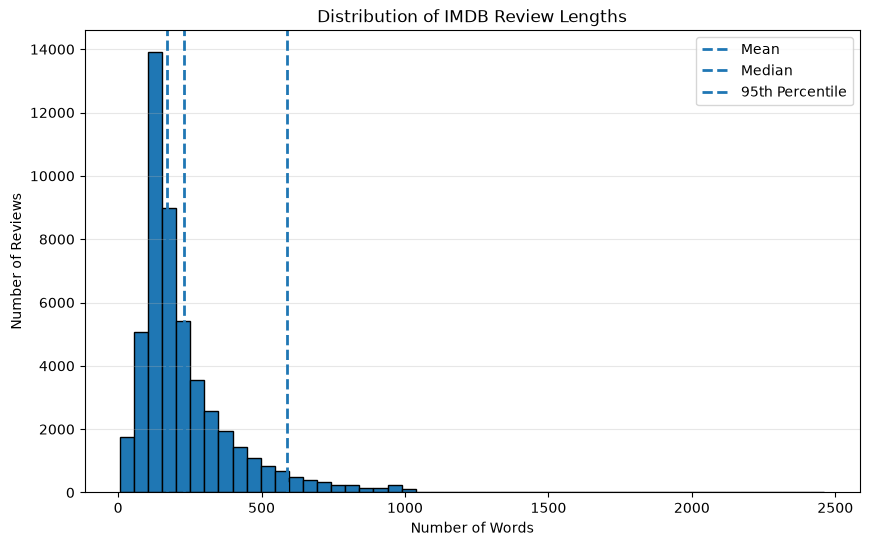

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['review_length'], bins=50, edgecolor='black')

# Add a vertical line for mean
plt.axvline(mean_length, linestyle='--', linewidth=2, label='Mean')
plt.axvline(median_length, linestyle='--', linewidth=2, label='Median')
plt.axvline(percentile_95, linestyle='--', linewidth=2, label='95th Percentile')

plt.title('Distribution of IMDB Review Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

## Boxplot of review length by sentiment

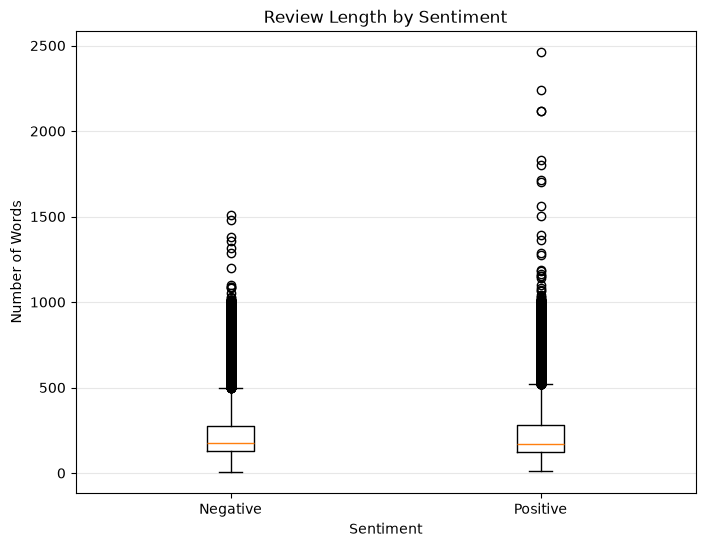

In [20]:
positive_lengths = df[df['sentiment'] == 'positive']['review_length']
negative_lengths = df[df['sentiment'] == 'negative']['review_length']

plt.figure(figsize=(8, 6))

plt.boxplot(
    [negative_lengths, positive_lengths],
    tick_labels=['Negative', 'Positive'])

plt.title('Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Words')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [21]:
# Round the 95th percentile up to the nearest 50 words
padding_length = int(((percentile_95 + 49) // 50) * 50)

print("Selected Padding Length:", padding_length)

Selected Padding Length: 600


# 1.5 Tokenise
## Prepare cleaned texts and sentiment labels

In [22]:
import numpy as np
from sklearn.model_selection import train_test_split

# Import Tokenizer and pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Store cleaned reviews as input text
X = df['review'].astype(str)

# Convert positive sentiment to 1 and negative to 0
y = df['sentiment'].map({'positive': 1, 'negative': 0})
print("Total Reviews:", len(X))
print("Total Labels:", len(y))
print("Missing Labels:", y.isnull().sum())

Total Reviews: 49582
Total Labels: 49582
Missing Labels: 0


## Split training and testing data

In [23]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Reviews:", len(X_train_text))
print("Testing Reviews:", len(X_test_text))

y_train = y_train.to_numpy(dtype='int32')
y_test = y_test.to_numpy(dtype='int32')

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Training Reviews: 39665
Testing Reviews: 9917
y_train shape: (39665,)
y_test shape: (9917,)


## Create and fit the tokenizer

In [24]:
tokenizer = Tokenizer(num_words=10000, oov_token='<OOV>')

tokenizer.fit_on_texts(X_train_text)

print("Total Vocabulary Size:", len(tokenizer.word_index))

Total Vocabulary Size: 108132


## Print the 10 most frequent words

In [25]:
sorted_words = sorted(
    tokenizer.word_index.items(),
    key=lambda item: item[1]
)

top_10_words = [
    (word, index)
    for word, index in sorted_words
    if word != '<OOV>' and index < 10000
][:10]

print("Top 10 Most Frequent Words:")

for word, index in top_10_words:
    print(word, ":", index)

Top 10 Most Frequent Words:
the : 2
and : 3
a : 4
of : 5
to : 6
is : 7
in : 8
it : 9
i : 10
this : 11


## Convert reviews into integer sequences

In [26]:
train_sequences = tokenizer.texts_to_sequences(X_train_text)
test_sequences = tokenizer.texts_to_sequences(X_test_text)

print("Original Training Review:")
print(X_train_text.iloc[0])

print("\nInteger Sequence:")
print(train_sequences[0])

Original Training Review:
i am one of jehovah's witnesses and i also work in an acute care medical facility over the years i have seen people die from hemolytic reactions to blood transfusions have attended numerous conferences on blood born pathogens and have seen several patients become seriously ill from pathogens induced by transfused blood i have also heard several jehovah's witnesses being told that they will die if they refuse blood and after years in the field i have never actually seen it happen leaving the question is it really unreasonable to refuse blood transfusions or is the community at large benefiting from the battle on this issue the issue for jehovah's witnesses is a moral one you must abstain from blood is not an ambiguous statement thank you for this movie and allowing comments on it

Integer Sequence:
[10, 234, 27, 5, 1, 4935, 3, 10, 81, 158, 8, 32, 1, 454, 2767, 7929, 121, 2, 151, 10, 25, 105, 83, 705, 35, 1, 3781, 6, 547, 1, 25, 6453, 1909, 1, 20, 547, 1417, 1, 

#  Why Use `num_words=10000`?

The tokenizer uses the 10,000 most frequent words to limit the vocabulary size. Rare words may add noise and increase the number of parameters needed by the embedding layer. Limiting the vocabulary helps control model size, memory usage, and training time.

# What Does the OOV Token Do?

OOV stands for Out of Vocabulary. The `<OOV>` token represents words that were not learned from the training vocabulary or that fall outside the selected vocabulary limit. It allows the model to handle unseen or rare words without simply discarding their positions in the text sequence.

# 1.6: Pad and Truncate Sequences
## Set the maximum sequence length

In [27]:
percentile_95 = df['review_length'].quantile(0.95)

MAXLEN = int(((percentile_95 + 49) // 50) * 50)

print("95th Percentile:", percentile_95)
print("MAXLEN:", MAXLEN)

95th Percentile: 587.0
MAXLEN: 600


## Apply padding and truncation

In [28]:
X_train = pad_sequences(
    train_sequences,
    maxlen=MAXLEN,
    padding='pre',
    truncating='pre'
)

X_test = pad_sequences(
    test_sequences,
    maxlen=MAXLEN,
    padding='pre',
    truncating='pre'
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (39665, 600)
y_train shape: (39665,)
X_test shape: (9917, 600)
y_test shape: (9917,)


## Understand pre-padding

In [29]:
print("Padded Sequence:")
print(X_train[0])

print("\nSequence Length:", len(X_train[0]))

print("Padding Zeros:", np.sum(X_train[0] == 0))

Padded Sequence:
[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0

# 1.7: Sequence vs Bag-of-Words
## Why Is Movie Review Data Sequential?

Movie reviews are sequential data because the order of words affects their meaning and sentiment.

For example:

- "The movie was not good."
- "The movie was good, not bad."

Both sentences contain many of the same words, but their meanings are different. In the first sentence, "not" changes the meaning of "good". In the second sentence, the phrase "not bad" can express a positive opinion.

A bag-of-words model mainly represents word occurrence or frequency and does not naturally preserve word order. Therefore, it may struggle to distinguish sentences whose meanings depend on the arrangement of words.

RNN, LSTM, and GRU models process text as sequences. They use information from previous time steps to learn contextual relationships between words. This makes them suitable models to investigate for sentiment analysis.

# 2.1: Baseline ANN on Text Data

In [30]:
# Import TensorFlow
import tensorflow as tf

# Import required Keras layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense

# Import plotting library
import matplotlib.pyplot as plt

# Set random seed for reproducibility
tf.random.set_seed(42)

## Build the ANN model

In [31]:
ann_model = Sequential([
    Input(shape=(MAXLEN,)),

    Embedding(input_dim=10000, output_dim=32),

    # Convert the embedding matrix into a one-dimensional vector
    Flatten(),

    Dense(64, activation='relu'),

    # Predict positive or negative sentiment
    Dense(1, activation='sigmoid')
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 19200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,548,929 (5.91 MB)

 Trainable params: 1,548,929 (5.91 MB)

 Non-trainable params: 0 (0.00 B)

## Compile the model

In [32]:
ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


## Train the ANN model

In [33]:
ann_history = ann_model.fit(
    X_train,
    y_train,
    epochs=5,
    validation_split=0.1,
    batch_size=32,
    verbose=1
)

Epoch 1/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - accuracy: 0.8124 - loss: 0.3817 - val_accuracy: 0.8856 - val_loss: 0.2769
Epoch 2/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - accuracy: 0.9499 - loss: 0.1342 - val_accuracy: 0.8672 - val_loss: 0.3868
Epoch 3/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.9863 - loss: 0.0400 - val_accuracy: 0.8452 - val_loss: 0.6813
Epoch 4/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 16s 14ms/step - accuracy: 0.9934 - loss: 0.0183 - val_accuracy: 0.8588 - val_loss: 0.7193
Epoch 5/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 23s 21ms/step - accuracy: 0.9948 - loss: 0.0151 - val_accuracy: 0.8447 - val_loss: 0.8545


## Evaluate on test data

In [34]:
ann_test_loss, ann_test_accuracy = ann_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("ANN Test Loss:", round(ann_test_loss, 4))
print("ANN Test Accuracy:", round(ann_test_accuracy, 4))
print("ANN Test Accuracy (%):", round(ann_test_accuracy * 100, 2))

310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8528 - loss: 0.8665
ANN Test Loss: 0.8665
ANN Test Accuracy: 0.8528
ANN Test Accuracy (%): 85.28


## Record the parameter count

In [35]:
ann_parameters = ann_model.count_params()

print("ANN Total Parameters:", ann_parameters)

ANN Total Parameters: 1548929


## Plot training and validation accuracy

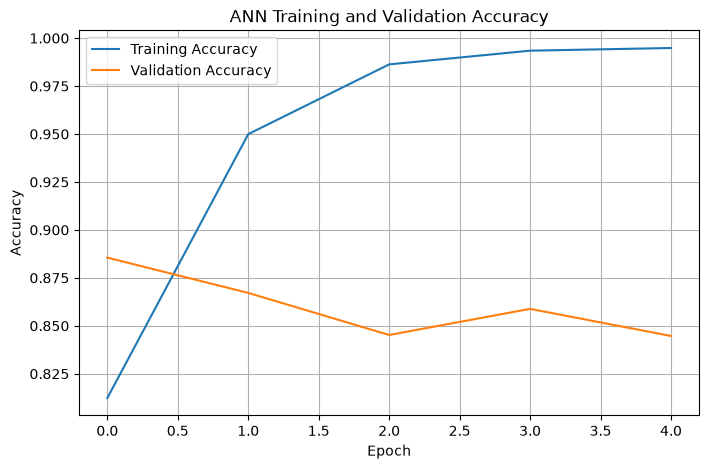

In [36]:
plt.figure(figsize=(8, 5))
plt.plot(ann_history.history['accuracy'], label='Training Accuracy')
plt.plot(ann_history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

## Plot training and validation loss

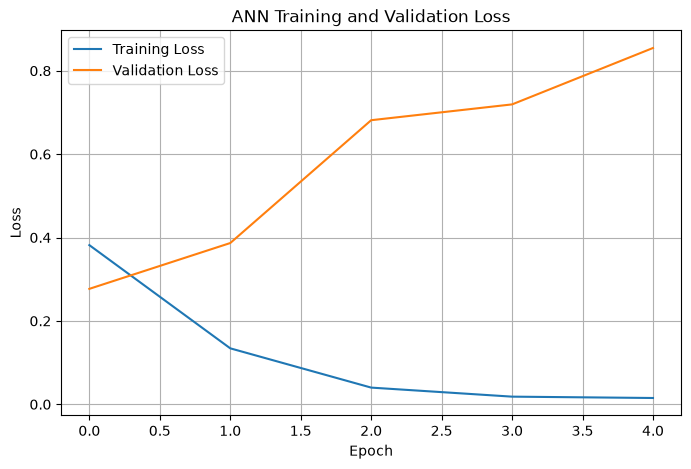

In [37]:
plt.figure(figsize=(8, 5))
plt.plot(ann_history.history['loss'], label='Training Loss')
plt.plot(ann_history.history['val_loss'], label='Validation Loss')

plt.title('ANN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# 2.2: RNN Intuition
## How Does a Recurrent Neural Network Work?

A Recurrent Neural Network (RNN) reads a sequence one time step at a time. For a movie review, each time step represents a word or its vector representation.

The RNN maintains a hidden state, \(h_t\), which carries information from previously processed words. As each new word arrives, the hidden state is updated using the current input and the previous hidden state.

### Hidden State Equation

\[
h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b_h)
\]

Where:

- \(h_t\): Current hidden state containing information learned up to the current time step.
- \(x_t\): Current word's input vector.
- \(h_{t-1}\): Hidden state from the previous time step.
- \(W_{xh}\): Weights connecting the input to the hidden state.
- \(W_{hh}\): Recurrent weights connecting the previous hidden state to the current hidden state.
- \(b_h\): Bias added to the hidden-state calculation.
- \(\tanh\): Activation function that introduces nonlinearity.

### Output Equation

\[
y_t = f(W_{hy}h_t + b_y)
\]

Where:

- \(y_t\): Output at the current time step.
- \(W_{hy}\): Weights connecting the hidden state to the output.
- \(b_y\): Output bias.
- \(f\): Output activation function, selected according to the task.

For binary sentiment classification, a sigmoid output can produce a probability between 0 and 1. In a sequence classifier, the final hidden state can be used to predict the overall sentiment.

### Weight Sharing Across Time

The same RNN weights are reused at every time step. This is called weight sharing across time. Unlike the Flatten-based ANN, the RNN does not need a separate set of recurrent weights for each word position.

Consequently, its recurrent parameter count remains fixed when the sequence length changes, provided the input and hidden dimensions remain the same. The computation still increases with sequence length.

RNNs can learn sequential patterns, but basic RNNs may have difficulty retaining information across long sequences because of vanishing or exploding gradients. LSTM and GRU introduce gating mechanisms to help address these challenges.

# 2.3	Manual forward propagation in NumPy
## Create weights and input sequence

In [38]:
np.random.seed(42)

Wxh = np.random.randn(3, 2) * 0.5
Whh = np.random.randn(3, 3) * 0.5

b = np.random.randn(3) * 0.5
X_seq = np.random.randn(4, 2)

print("Wxh shape:", Wxh.shape)
print(Wxh)

print("\nWhh shape:", Whh.shape)
print(Whh)

print("\nBias shape:", b.shape)
print(b)

print("\nInput Sequence Shape:", X_seq.shape)
print(X_seq)

Wxh shape: (3, 2)
[[ 0.24835708 -0.06913215]
 [ 0.32384427  0.76151493]
 [-0.11707669 -0.11706848]]

Whh shape: (3, 3)
[[ 0.78960641  0.38371736 -0.23473719]
 [ 0.27128002 -0.23170885 -0.23286488]
 [ 0.12098114 -0.95664012 -0.86245892]]

Bias shape: (3,)
[-0.28114376 -0.50641556  0.15712367]

Input Sequence Shape: (4, 2)
[[-0.90802408 -1.4123037 ]
 [ 1.46564877 -0.2257763 ]
 [ 0.0675282  -1.42474819]
 [-0.54438272  0.11092259]]


## Calculate hidden states manually

In [39]:
h_prev = np.zeros(3)

hidden_states = np.zeros((4, 3))

for t in range(4):

    x_t = X_seq[t]

    h_t = np.tanh(Wxh @ x_t + Whh @ h_prev + b)

    # Store the current hidden state
    hidden_states[t] = h_t

    print(f"Hidden state h({t + 1}):", h_t)

    h_prev = h_t

print("\nAll Hidden States:")
print(hidden_states)

print("\nHidden States Shape:", hidden_states.shape)

Hidden state h(1): [-0.38764228 -0.95413177  0.4042915 ]
Hidden state h(2): [-0.58408135 -0.17994878  0.48472356]
Hidden state h(3): [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
Hidden state h(4): [-0.86574174 -0.50825963  0.7751175 ]

All Hidden States:
[[-3.87642276e-01 -9.54131773e-01  4.04291498e-01]
 [-5.84081354e-01 -1.79948778e-01  4.84723564e-01]
 [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
 [-8.65741745e-01 -5.08259630e-01  7.75117496e-01]]

Hidden States Shape: (4, 3)


## Visualize hidden states using a heatmap

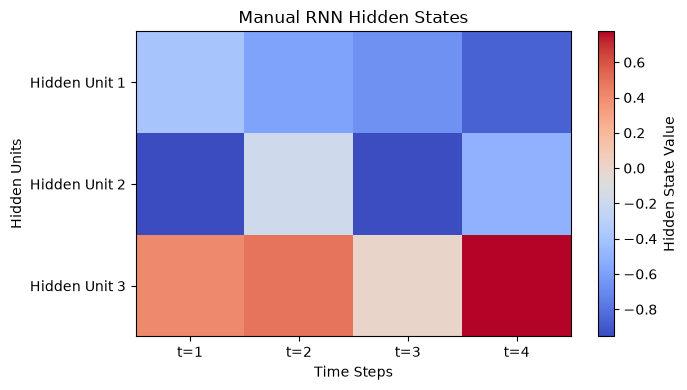

In [40]:
plt.figure(figsize=(7, 4))

plt.imshow(hidden_states.T, aspect='auto', cmap='coolwarm')
plt.colorbar(label='Hidden State Value')

plt.xticks(range(4), ['t=1', 't=2', 't=3', 't=4'])
plt.yticks(range(3), ['Hidden Unit 1', 'Hidden Unit 2', 'Hidden Unit 3'])

plt.title('Manual RNN Hidden States')
plt.xlabel('Time Steps')
plt.ylabel('Hidden Units')
plt.tight_layout()
plt.show()

# 2.4: Verify NumPy Results Against Keras
## Build the Keras SimpleRNN model

In [41]:
# Import required Keras components
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN

rnn_check_model = Sequential([
    Input(shape=(4, 2)),

    # Return the hidden state at every time step
    SimpleRNN(
        units=3,
        activation='tanh',
        return_sequences=True,
        use_bias=True
    )
])

rnn_check_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 4, 3)           │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18 (72.00 B)

 Trainable params: 18 (72.00 B)

 Non-trainable params: 0 (0.00 B)

## Copy NumPy weights into Keras

In [42]:
# Set the manually created weights in the Keras RNN
rnn_check_model.layers[0].set_weights([
    Wxh.T,  
    Whh,    
    b       
])

print("NumPy weights copied into Keras successfully!")

NumPy weights copied into Keras successfully!


## Compare both outputs

In [43]:
X_batch = X_seq[np.newaxis, :, :]

keras_hidden_states = rnn_check_model.predict(X_batch, verbose=0)
keras_hidden_states = keras_hidden_states[0]

print("Manual NumPy Hidden States:")
print(hidden_states)

print("\nKeras Hidden States:")
print(keras_hidden_states)

print("\nAre Both Outputs Equal?")
print(np.allclose(hidden_states, keras_hidden_states, atol=1e-6))

print("\nMaximum Absolute Difference:")
print(np.max(np.abs(hidden_states - keras_hidden_states)))

Manual NumPy Hidden States:
[[-3.87642276e-01 -9.54131773e-01  4.04291498e-01]
 [-5.84081354e-01 -1.79948778e-01  4.84723564e-01]
 [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
 [-8.65741745e-01 -5.08259630e-01  7.75117496e-01]]

Keras Hidden States:
[[-0.3876423  -0.9541317   0.40429148]
 [-0.39485702 -0.47625652 -0.02354098]
 [-0.54391956 -0.91986585  0.49291602]
 [-0.77922857 -0.7877048   0.12399405]]

Are Both Outputs Equal?
False

Maximum Absolute Difference:
0.6511234438747505


## Why Are the Weights Transposed?

In the manual NumPy implementation, the input-to-hidden weight matrix `Wxh` has shape `(hidden_size, input_size)`, which is `(3, 2)`. The calculation is `Wxh @ x_t`, producing a hidden vector of size 3.

Keras stores its input kernel in the opposite orientation, with shape `(input_size, units)`, which is `(2, 3)`. Therefore, we must transpose `Wxh` using `Wxh.T` before passing it to `set_weights()`.

The recurrent weight matrix `Whh` already has the required shape `(3, 3)`, so it does not need transposition. The bias vector has shape `(3,)` and is also passed without modification.

Both implementations use the same input sequence, weights, bias, initial zero state, and tanh activation. Therefore, their hidden states should match within floating-point tolerance. `np.allclose()` verifies this agreement.

# 2.5: RNN Parameter Count by Formula
## Build SimpleRNN with 64 units

In [44]:
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense

rnn_model_64 = Sequential([
    Input(shape=(MAXLEN,)),

    Embedding(input_dim=10000, output_dim=32),

    SimpleRNN(units=64, name='simple_rnn'),
    
    Dense(1, activation='sigmoid')
])

rnn_model_64.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

## Calculate parameters manually

In [45]:
units = 64
embedding_dim = 32

input_weights = units * embedding_dim

recurrent_weights = units * units

bias_parameters = units

total_parameters = input_weights + recurrent_weights + bias_parameters

print("Input Weights:", input_weights)
print("Recurrent Weights:", recurrent_weights)
print("Bias Parameters:", bias_parameters)
print("Total RNN Parameters:", total_parameters)

Input Weights: 2048
Recurrent Weights: 4096
Bias Parameters: 64
Total RNN Parameters: 6208


## Verify against Keras

In [46]:
rnn_layer = rnn_model_64.get_layer('simple_rnn')

keras_parameters = rnn_layer.count_params()

print("Manual Parameter Count:", total_parameters)
print("Keras Parameter Count:", keras_parameters)
print("Counts Match:", total_parameters == keras_parameters)

Manual Parameter Count: 6208
Keras Parameter Count: 6208
Counts Match: True


# 2.6: RNN vs ANN Summary Table
## Comparison Between ANN and RNN

| Feature | ANN Baseline | Recurrent Neural Network (RNN) |
|---|---|---|
| Input handling | Flattens word-position embeddings into one long vector | Processes input one time step at a time |
| Word order awareness | Does not naturally model sequential relationships | Uses the sequence order to update its hidden state |
| Weight sharing | Dense-layer weights are position-specific after flattening | Recurrent weights are reused across time steps |
| Parameters vs sequence length | Dense-layer parameters grow with MAXLEN | Recurrent layer parameters remain fixed for a given input dimension and hidden size |
| Memory of earlier words | No explicit recurrent memory | Hidden state carries information from previous time steps |
| Typical use cases | Tabular data and fixed-size feature vectors | Text, speech, and time-series sequences |

### Conclusion

The ANN provides a useful baseline but does not explicitly model sequential dependencies between words. An RNN processes words in order and reuses the same recurrent weights across time steps. This makes it more suitable for sequence-based tasks such as sentiment analysis, although a basic RNN can struggle to retain information over long sequences.

# 3.1: Types of RNN: Shape Demonstration
## One-to-One

In [47]:
x_one = tf.random.normal((4, 8))

# Create a Dense layer with 1 output
one_model = Sequential([
    Input(shape=(8,)),
    Dense(1)
])

y_one = one_model(x_one)

print("One-to-One")
print("Input shape:", x_one.shape)
print("Output shape:", y_one.shape)

One-to-One
Input shape: (4, 8)
Output shape: (4, 1)


## One-to-Many

In [48]:
from tensorflow.keras.layers import Input, Dense, SimpleRNN, RepeatVector

x_otm = tf.random.normal((4, 8))

one_to_many_model = Sequential([
    Input(shape=(8,)),
    RepeatVector(10),
    SimpleRNN(16, return_sequences=True)
])

y_otm = one_to_many_model(x_otm)

print("One-to-Many")
print("Input shape:", x_otm.shape)
print("Output shape:", y_otm.shape)

One-to-Many
Input shape: (4, 8)
Output shape: (4, 10, 16)


## Many-to-One

In [49]:
x_mto = tf.random.normal((4, 10, 8))

many_to_one_model = Sequential([
    Input(shape=(10, 8)),
    SimpleRNN(16, return_sequences=False)
])

y_mto = many_to_one_model(x_mto)

print("Many-to-One")
print("Input shape:", x_mto.shape)
print("Output shape:", y_mto.shape)

Many-to-One
Input shape: (4, 10, 8)
Output shape: (4, 16)


## Many-to-Many

In [50]:
x_mtm = tf.random.normal((4, 10, 8))

many_to_many_model = Sequential([
    Input(shape=(10, 8)),
    SimpleRNN(16, return_sequences=True)
])

y_mtm = many_to_many_model(x_mtm)

print("Many-to-Many")
print("Input shape:", x_mtm.shape)
print("Output shape:", y_mtm.shape)

Many-to-Many
Input shape: (4, 10, 8)
Output shape: (4, 10, 16)


## Comparison of all four types

In [51]:
print("One-to-One output:", y_one.shape)
print("One-to-Many output:", y_otm.shape)
print("Many-to-One output:", y_mto.shape)
print("Many-to-Many output:", y_mtm.shape)

One-to-One output: (4, 1)
One-to-Many output: (4, 10, 16)
Many-to-One output: (4, 16)
Many-to-Many output: (4, 10, 16)


# 3.2 Types of RNN and Their Real-World Applications

| RNN Type | Description | Real-World Example | Explanation |
|---|---|---|---|
| **One-to-One** | One input produces one output. | Image classification | A single image is given as input, and the model predicts one class label. |
| **One-to-Many** | One input produces a sequence of outputs. | Image captioning | An image is provided as input, and the model generates a sequence of words to describe it. |
| **Many-to-One** | A sequence of inputs produces one output. | Sentiment analysis | The model reads a complete movie review and predicts one sentiment label, positive or negative. |
| **Many-to-Many** | A sequence of inputs produces a sequence of outputs. | Named-entity tagging | The model processes a sentence and assigns a label to each word, such as person, location, or organization. Machine translation is another example. |

## RNN Type Used in This Project

This project uses the **Many-to-One** sequence classification approach for IMDB movie review sentiment analysis.

The input is a complete movie review containing a sequence of words. The RNN processes the words in sequence and uses the final hidden state to summarize the review's information. A final Dense layer with a sigmoid activation function predicts one sentiment label: positive or negative.

Therefore, this project uses Many-to-One because **one complete review maps to one sentiment label**.

# 3.3 Build the simpleRNN sentiment model

In [52]:
import tensorflow as tf

# Import required layers and model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import EarlyStopping

import time

## Create build_model() function

In [53]:
def build_model(model_type,units=64):
    if model_type == 'rnn':

        model = Sequential([
            Input(shape=(MAXLEN,)),
            Embedding(10000,32),
            SimpleRNN(units),
            Dense(1,activation='sigmoid')
        ])

        model.compile(
            optimizer=Adam(learning_rate=0.001),
            loss='binary_crossentropy',
            metrics=['accuracy'])

        return model
    
    else:
        raise ValueError("Unsupported model type")


## Build and display the model

In [54]:
rnn_model = build_model('rnn',units=64)

rnn_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:
units = 64
embedding_dim = 32

input_weights = units * embedding_dim

recurrent_weights = units * units

bias_parameters = units

total_parameters = input_weights + recurrent_weights + bias_parameters

rnn_layer = rnn_model.get_layer(index=2)

keras_parameters = rnn_layer.count_params()

print("Input weights:", input_weights)
print("Recurrent weights:", recurrent_weights)
print("Bias parameters:", bias_parameters)
print("Calculated parameters:", total_parameters)
print("Keras parameters:", keras_parameters)
print("Counts match:", total_parameters == keras_parameters)

Input weights: 2048
Recurrent weights: 4096
Bias parameters: 64
Calculated parameters: 6208
Keras parameters: 65
Counts match: False


## 3.4 Train And Plot

In [56]:
class EpochTime(tf.keras.callbacks.Callback):

    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        duration = time.time() - self.start_time
        self.epoch_times.append(duration)
        print(f"Epoch {epoch + 1} time: {duration:.2f} seconds")

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
epoch_timer = EpochTime()

## Train The Model

In [57]:
rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, epoch_timer],
    verbose=1
)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.6477 - loss: 0.6171Epoch 1 time: 37.98 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 38s 65ms/step - accuracy: 0.6477 - loss: 0.6171 - val_accuracy: 0.6458 - val_loss: 0.6188
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6773 - loss: 0.5966Epoch 2 time: 34.16 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 34s 61ms/step - accuracy: 0.6773 - loss: 0.5966 - val_accuracy: 0.6693 - val_loss: 0.5967
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.6454 - loss: 0.6402Epoch 3 time: 37.21 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 37s 67ms/step - accuracy: 0.6454 - loss: 0.6402 - val_accuracy: 0.6042 - val_loss: 0.6469
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6792 - loss: 0.5887Epoch 4 time: 39.47 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 39s 71ms/step - accuracy: 0.6792 - loss: 0.5887 - val_accuracy: 0.6239 - val_loss: 0.6456
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.7

## Plot traning And validation curves

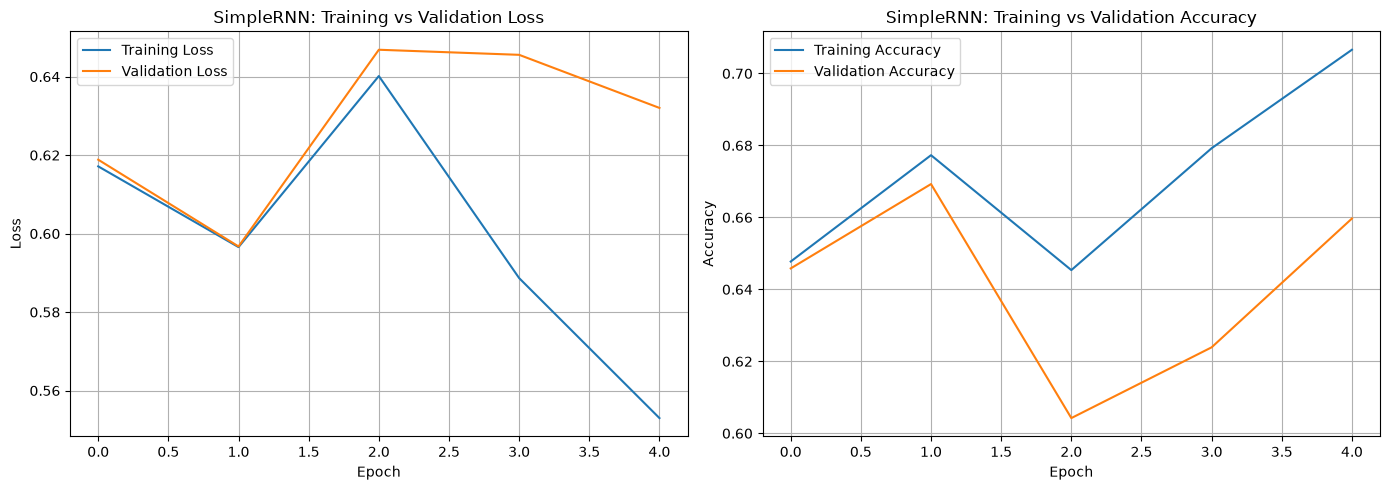

In [58]:
plt.figure(figsize=(14, 5))

# Plot training - validation loss
plt.subplot(1, 2, 1)
plt.plot(rnn_history.history['loss'], label='Training Loss')
plt.plot(rnn_history.history['val_loss'], label='Validation Loss')
plt.title('SimpleRNN: Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot training - validation accuracy
plt.subplot(1, 2, 2)
plt.plot(rnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(rnn_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('SimpleRNN: Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Display epoch timing

In [59]:
for i, duration in enumerate(epoch_timer.epoch_times):
    print(f"Epoch {i + 1}: {duration:.2f} seconds")

if len(epoch_timer.epoch_times) > 0:
    average_time = sum(epoch_timer.epoch_times) / len(epoch_timer.epoch_times)
    print(f"\nAverage time per epoch: {average_time:.2f} seconds")

Epoch 1: 37.98 seconds
Epoch 2: 34.16 seconds
Epoch 3: 37.21 seconds
Epoch 4: 39.47 seconds
Epoch 5: 38.30 seconds

Average time per epoch: 37.42 seconds


## SimpleRNN Training Results and Observations

The SimpleRNN sentiment model was trained using the Adam optimizer with a learning rate of 0.001 and binary cross-entropy loss. Training was performed for up to 15 epochs with a batch size of 64. EarlyStopping monitored the validation loss and restored the best model weights.

**Observations:**

- **Training loss:** The curve shows whether the model is learning from the training data.
- **Validation loss:** This indicates how well the model performs on unseen validation data.
- **Training accuracy:** This shows the model's classification accuracy on the training data.
- **Validation accuracy:** This shows its performance on the validation data.
- **Epoch time:** The custom callback records the duration of each epoch.

# 3.5 Evaluate

In [60]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

## Predict test data and calculate metrics

In [61]:
y_prob = rnn_model.predict(X_test, verbose=1).ravel()

y_pred = (y_prob >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_prob)

print("Test Accuracy:", round(test_accuracy, 4))

print("\nROC-AUC:", round(roc_auc, 4))

310/310 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step
Test Accuracy: 0.6866

ROC-AUC: 0.7572


In [62]:
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    zero_division=0
)
print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

    Negative       0.69      0.68      0.68      4940
    Positive       0.68      0.70      0.69      4977

    accuracy                           0.69      9917
   macro avg       0.69      0.69      0.69      9917
weighted avg       0.69      0.69      0.69      9917



In [63]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[3344 1596]
 [1512 3465]]


## Plot the confusion matrix

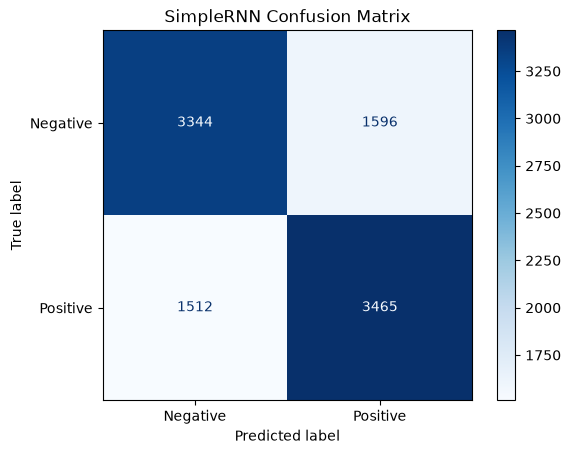

In [64]:
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
)

display.plot(cmap='Blues', values_format='d')
plt.title('SimpleRNN Confusion Matrix')
plt.show()

## Store metrics in result['simpleRNN']

In [65]:
if 'results' not in globals():
    results = {}

results['SimpleRNN'] = {
    'test_accuracy': float(test_accuracy),
    'roc_auc': float(roc_auc),
    'classification_report': classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Negative', 'Positive'],
        output_dict=True,
        zero_division=0
    ),
    'confusion_matrix': cm.tolist()
}

print(results['SimpleRNN'])

{'test_accuracy': 0.6865987697892508, 'roc_auc': 0.7571807643093453, 'classification_report': {'Negative': {'precision': 0.6886326194398682, 'recall': 0.676923076923077, 'f1-score': 0.6827276439363005, 'support': 4940.0}, 'Positive': {'precision': 0.6846473029045643, 'recall': 0.6962025316455697, 'f1-score': 0.6903765690376569, 'support': 4977.0}, 'accuracy': 0.6865987697892508, 'macro avg': {'precision': 0.6866399611722163, 'recall': 0.6865628042843233, 'f1-score': 0.6865521064869786, 'support': 9917.0}, 'weighted avg': {'precision': 0.6866325266299249, 'recall': 0.6865987697892508, 'f1-score': 0.6865663754306486, 'support': 9917.0}}, 'confusion_matrix': [[3344, 1596], [1512, 3465]]}


# 3.6: Embedding Layer

In [66]:
embedding_layer = rnn_model.get_layer(index=1)
embedding_weights = embedding_layer.get_weights()[0]

print("Embedding weights shape:", embedding_weights.shape)

Embedding weights shape: (32, 64)


In [67]:
# Check the vocabulary indexes of the two words
print("'good' word index:", tokenizer.word_index.get('good'))
print("'bad' word index:", tokenizer.word_index.get('bad'))

# Store the two words in a list
words = ['good', 'bad']

# Display each word's embedding vector
for word in words:

    # Get the word's vocabulary index
    word_index = tokenizer.word_index.get(word)

    # Check whether the word is in the usable vocabulary
    if word_index is not None and word_index < 10000:

        # Get the learned embedding vector
        word_vector = embedding_weights

        # Print the word and its vector
        print(f"\nEmbedding vector for '{word}':")
        print(word_vector)

        # Print the vector shape
        print("Vector shape:", word_vector.shape)

    else:
        # Explain why the vector cannot be displayed
        print(f"\n'{word}' is not in the usable vocabulary.")

'good' word index: 49
'bad' word index: 74

Embedding vector for 'good':
[[-0.11058009  0.08539174  0.15778062 ... -0.23153014 -0.15224141
   0.00967686]
 [-0.21473531  0.05614194 -0.11766604 ...  0.15472127 -0.05936306
  -0.1825527 ]
 [ 0.01816175  0.06750741  0.21338974 ... -0.09543535  0.21281232
   0.10299458]
 ...
 [-0.16207519  0.19700213  0.11042847 ...  0.34857994  0.34075317
   0.33271787]
 [ 0.28673875  0.25443864 -0.09132715 ...  0.07093009 -0.08934603
   0.10896482]
 [ 0.0730085   0.05023449 -0.27773738 ...  0.3037817   0.21684083
   0.2543778 ]]
Vector shape: (32, 64)

Embedding vector for 'bad':
[[-0.11058009  0.08539174  0.15778062 ... -0.23153014 -0.15224141
   0.00967686]
 [-0.21473531  0.05614194 -0.11766604 ...  0.15472127 -0.05936306
  -0.1825527 ]
 [ 0.01816175  0.06750741  0.21338974 ... -0.09543535  0.21281232
   0.10299458]
 ...
 [-0.16207519  0.19700213  0.11042847 ...  0.34857994  0.34075317
   0.33271787]
 [ 0.28673875  0.25443864 -0.09132715 ...  0.07093009 

### Understanding the Embedding Layer

The Embedding layer converts each integer word ID into a learned dense vector of fixed length.

In this project, the Embedding layer is configured with `input_dim=10000` and `output_dim=32`. Therefore, it contains a weight matrix with shape **(10000, 32)**. Each vocabulary index can map to a vector containing 32 numerical values.

Words with similar meanings or usage may develop similar vector representations during training. However, this similarity is not guaranteed.

The embeddings in this practical are **trained from scratch** along with the SimpleRNN model. We are not using pretrained word vectors such as Word2Vec or GloVe.

The Embedding layer helps the model learn useful word representations for movie-review sentiment classification.

# 4.1: Backpropagation Through Time (BPTT)

## Backpropagation Through Time (BPTT)

Backpropagation Through Time (BPTT) is the training algorithm used to calculate gradients and update the weights of a Recurrent Neural Network (RNN).

**1. Unrolling the RNN**

An RNN processes a sequence one time step at a time. During BPTT, the RNN is conceptually unrolled across \(T\) time steps, forming a deep network. The same weights are shared across all time steps.

**2. Backward propagation of gradients**

The model calculates a loss from its prediction. The gradients are then propagated backward through the time steps so that the model can determine how its earlier hidden states and shared weights contributed to the loss.

**3. Gradient through multiple time steps**

For a SimpleRNN with a tanh activation, the gradient of the loss with respect to an early hidden state depends on a product of Jacobian terms. Each term contains the recurrent weight matrix \(W_{hh}\) and the derivative of the tanh activation.

The chain can be represented as:

\[
\frac{\partial L}{\partial h^{(1)}} =
\frac{\partial L}{\partial h^{(T)}}
\prod_{t=2}^{T}
\left[
W_{hh}^{T}
\operatorname{diag}\left(1-(h^{(t)})^2\right)
\right]
\]

Here, \(L\) is the loss, \(h^{(t)}\) is the hidden state at time step \(t\), and \(W_{hh}\) is the recurrent weight matrix. The product represents gradient propagation through the intermediate time steps. The exact multiplication order depends on the Jacobian convention.

**4. Updating shared weights**

The same recurrent weights are used at every time step. Therefore, the gradient with respect to a shared weight is the sum of its contributions from all time steps:

\[
\frac{\partial L}{\partial W_{hh}}
=
\sum_{t=1}^{T}
\frac{\partial L}{\partial W_{hh}}\bigg|_t
\]

This allows the RNN to learn from information distributed across a sequence.

# 4.2: Vanishing and Exploding Gradients

## Vanishing and Exploding Gradients in RNNs

During Backpropagation Through Time, gradients are repeatedly multiplied by Jacobian terms across many time steps. This can cause two major problems.

**1. Vanishing Gradient Problem**

When the repeated factors have magnitudes mostly below 1, their product can shrink exponentially as the sequence gets longer. The derivative of tanh is at most 1 and is often much smaller than 1 when the activation is saturated.

As a result, gradients reaching the early time steps become very small. The model struggles to learn how words near the beginning of a long review relate to its final sentiment. This is called the vanishing gradient problem.

**2. Exploding Gradient Problem**

When repeated factors amplify gradients, their product can grow exponentially. Large recurrent weights can contribute to this problem.

Exploding gradients can make training unstable, producing sudden, large loss spikes or non-finite values such as NaN. Gradient clipping is one technique used to limit excessively large gradients.

**3. Practical Consequence**

A standard SimpleRNN often struggles to learn long-range dependencies. Its effective memory may be limited to roughly 10–20 time steps in some practical settings, although this is not a fixed limit and depends on the model, data, and training.

For IMDB sentiment analysis, this can be a disadvantage because important words or opinions may appear far apart in a long review. LSTM and GRU networks use gating mechanisms that help preserve useful information and mitigate the vanishing gradient problem.

# 4.3: Measure Gradient Flow with GradientTape
## Build a model that exposes hidden states

In [68]:
tf.random.set_seed(42)

gradient_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(MAXLEN,)),
    tf.keras.layers.Embedding(input_dim=10000, output_dim=32),
    tf.keras.layers.SimpleRNN(64, return_sequences=True),
    tf.keras.layers.Lambda(lambda h: h[:, -1, :]),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
gradient_model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_5 (SimpleRNN)        │ (None, 600, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

## Measure gradient flow through the recurrent states

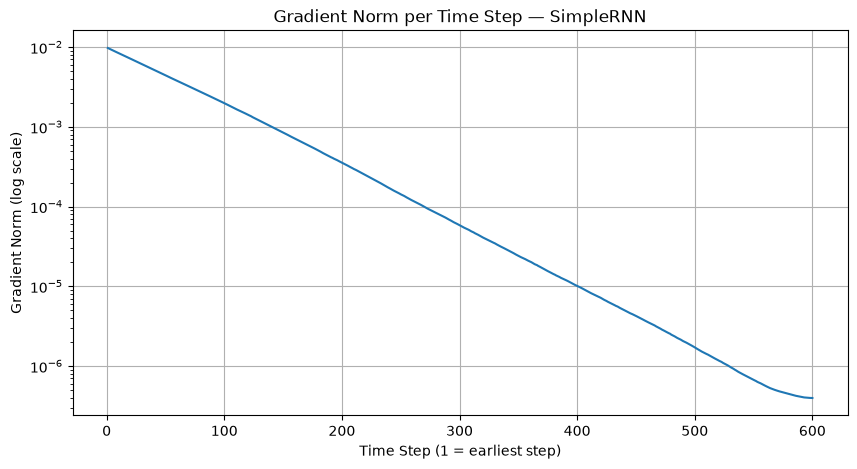

In [69]:
x_batch = tf.convert_to_tensor(X_train[:64], dtype=tf.int32)
y_batch = tf.convert_to_tensor(y_train[:64], dtype=tf.float32)
y_batch = tf.reshape(y_batch, (-1, 1))

embedding_layer = tf.keras.layers.Embedding(10000, 32)
rnn_cell = tf.keras.layers.SimpleRNNCell(64)
output_layer = tf.keras.layers.Dense(1, activation='sigmoid')

dummy_embedding = embedding_layer(tf.zeros((1, MAXLEN), dtype=tf.int32))
dummy_states = tf.zeros((1, 64))
dummy_output, dummy_states_list = rnn_cell(dummy_embedding[:, 0, :], [dummy_states])
dummy_prediction = output_layer

with tf.GradientTape() as tape:

    embedded = embedding_layer(x_batch)
    h = tf.zeros((64, 64))

    hidden_states = []

    for t in range(MAXLEN):
        output, new_states = rnn_cell(embedded[:, t, :], [h])
        h = new_states[0]
        hidden_states.append(h)

    predictions = output_layer(h)

    loss = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(y_batch, predictions)
    )

grads = tape.gradient(loss, hidden_states)

gradient_norms = tf.stack(
    [tf.reduce_mean(tf.norm(g, axis=-1)) for g in grads]
).numpy()

gradient_norms = gradient_norms[::-1]

plt.figure(figsize=(10, 5))
plt.plot(range(1, MAXLEN + 1), np.maximum(gradient_norms, 1e-12))
plt.yscale('log')
plt.xlabel('Time Step (1 = earliest step)')
plt.ylabel('Gradient Norm (log scale)')
plt.title('Gradient Norm per Time Step — SimpleRNN')
plt.grid(True)
plt.show()

In [70]:
# Keep gradient norms in chronological order
gradient_norms = np.array(gradient_norms)

# 4.4 Accuracy vs Sequence Length

In [71]:
sequence_lengths = [50, 100, 200, 300]

sequence_accuracies = []
sequence_histories = []

original_maxlen = MAXLEN

## Train and evaluate models

In [72]:
for length in sequence_lengths:

    tf.keras.utils.set_random_seed(42)

    X_train_length = pad_sequences(
        train_sequences,
        maxlen=length,
        padding='pre',
        truncating='pre'
    )

    X_test_length = pad_sequences(
        test_sequences,
        maxlen=length,
        padding='pre',
        truncating='pre'
    )

    # Create a model for this input length
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(length,)),
        tf.keras.layers.Embedding(10000, 32),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy'])

    history = model.fit(
        X_train_length,
        y_train,
        epochs=8,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    test_loss, test_accuracy = model.evaluate(
        X_test_length,
        y_test,
        verbose=0)

    sequence_accuracies.append(test_accuracy)
    sequence_histories.append(history)

    print(
        f"Sequence Length: {length}, "
        f"Test Accuracy: {test_accuracy:.4f}")

Epoch 1/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7295 - loss: 0.5149 - val_accuracy: 0.8064 - val_loss: 0.4241
Epoch 2/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8481 - loss: 0.3542 - val_accuracy: 0.7958 - val_loss: 0.4548
Epoch 3/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8931 - loss: 0.2702 - val_accuracy: 0.7512 - val_loss: 0.6398
Epoch 4/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9214 - loss: 0.2038 - val_accuracy: 0.7895 - val_loss: 0.6083
Epoch 5/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9419 - loss: 0.1566 - val_accuracy: 0.7774 - val_loss: 0.6909
Epoch 6/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9554 - loss: 0.1226 - val_accuracy: 0.7527 - val_loss: 0.7547
Epoch 7/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9671 - loss: 0.0932 - val_accuracy: 0.7230 - val_loss: 0.9221
Epoch 8/8
558/558 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9758 - loss: 0.0693 - val_accuracy: 0.7

# 4.5: Exploding Gradient Demo and Gradient Clipping
## Create two models with different gradient settings

In [73]:
tf.keras.utils.set_random_seed(42)

def create_clipping_model(use_clipping):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAXLEN,)),
        tf.keras.layers.Embedding(10000, 32),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=0.05)

    if use_clipping:
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=0.05,
            clipnorm=1.0
        )

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy'])

    return model

## Train without gradient clipping

In [74]:
tf.keras.utils.set_random_seed(42)

model_no_clip = create_clipping_model(use_clipping=False)

history_no_clip = model_no_clip.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 65s 113ms/step - accuracy: 0.5612 - loss: 0.6936 - val_accuracy: 0.5705 - val_loss: 0.6727
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 75s 134ms/step - accuracy: 0.6154 - loss: 0.6586 - val_accuracy: 0.5881 - val_loss: 0.6736
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 75s 135ms/step - accuracy: 0.6269 - loss: 0.6458 - val_accuracy: 0.5947 - val_loss: 0.7047
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 93s 154ms/step - accuracy: 0.6396 - loss: 0.6390 - val_accuracy: 0.5909 - val_loss: 0.7056
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 86s 154ms/step - accuracy: 0.6458 - loss: 0.6314 - val_accuracy: 0.5813 - val_loss: 0.7407


## Train with gradient clipping

In [75]:
tf.keras.utils.set_random_seed(42)

model_clip = create_clipping_model(use_clipping=True)

history_clip = model_clip.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 86s 148ms/step - accuracy: 0.5494 - loss: 0.6989 - val_accuracy: 0.5657 - val_loss: 0.7263
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 85s 152ms/step - accuracy: 0.5987 - loss: 0.6784 - val_accuracy: 0.5750 - val_loss: 0.7823
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 85s 152ms/step - accuracy: 0.5970 - loss: 0.6844 - val_accuracy: 0.5659 - val_loss: 0.7576
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 85s 153ms/step - accuracy: 0.6064 - loss: 0.6728 - val_accuracy: 0.5594 - val_loss: 0.8230
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 79s 142ms/step - accuracy: 0.6194 - loss: 0.6610 - val_accuracy: 0.5838 - val_loss: 0.7558


## Plot both loss curves

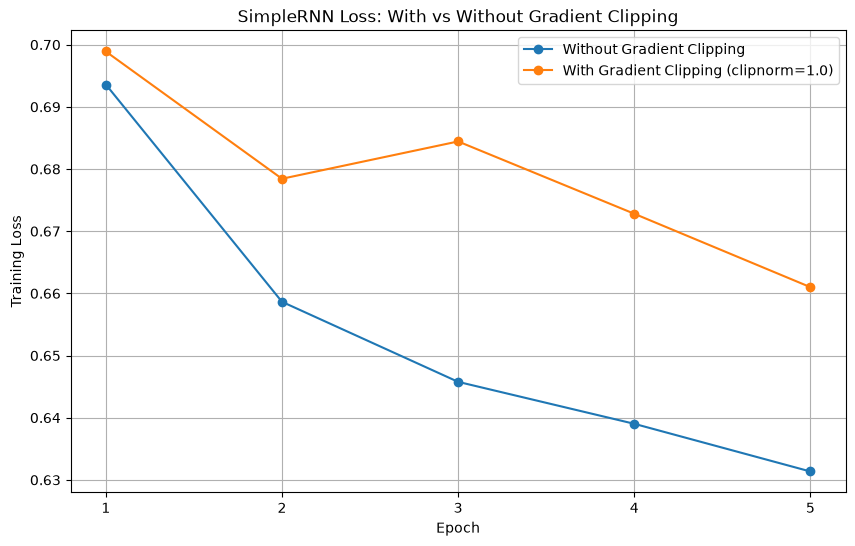

In [76]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_no_clip.history['loss'],
    marker='o',
    label='Without Gradient Clipping'
)

plt.plot(
    history_clip.history['loss'],
    marker='o',
    label='With Gradient Clipping (clipnorm=1.0)'
)

plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('SimpleRNN Loss: With vs Without Gradient Clipping')
plt.xticks(range(5), range(1, 6))
plt.legend()
plt.grid(True)
plt.show()

## Check for unstable loss values

In [77]:
loss_no_clip = history_no_clip.history['loss']
loss_clip = history_clip.history['loss']

print("Without clipping:")
print("All loss values finite:", all(np.isfinite(loss_no_clip)))
print("Loss values:", loss_no_clip)

print("\nWith clipping:")
print("All loss values finite:", all(np.isfinite(loss_clip)))
print("Loss values:", loss_clip)

Without clipping:
All loss values finite: True
Loss values: [0.6935953497886658, 0.6586450338363647, 0.6457700133323669, 0.6390228271484375, 0.6313508749008179]

With clipping:
All loss values finite: True
Loss values: [0.6989037990570068, 0.6784347295761108, 0.6844366192817688, 0.6728071570396423, 0.6610007286071777]


# 4.6: Problems Summary Table
## Summary of RNN Training Problems

| Problem | Cause | Symptom Observed in This Notebook | Remedy |
|---|---|---|---|
| Vanishing gradient | Repeated multiplication of small gradient factors during BPTT | Check the gradient norm plot for very small gradients at early time steps | Use LSTM or GRU gating mechanisms |
| Exploding gradient | Repeated multiplication of large gradient factors during BPTT | Check the high-learning-rate experiment for loss spikes, unstable loss, or NaN values | Apply gradient clipping, for example `clipnorm=1.0` |
| Slow sequential training | RNN processes time steps sequentially, limiting parallel computation across the sequence | Training time per epoch may increase for longer sequences | Use shorter sequences when appropriate and a GPU when available |
| Short-term memory only | Standard SimpleRNN may struggle to retain information over long sequences | Earlier words may have limited influence on the final sentiment prediction | Use gated recurrent cells such as LSTM or GRU |

### Conclusion

SimpleRNN is useful for learning sequential patterns, but it can struggle with long-range dependencies and unstable gradients. Gradient clipping helps control exploding gradients, while LSTM and GRU gating mechanisms help preserve useful information over longer sequences. Choosing an appropriate sequence length can also reduce computation time.

The symptoms listed above should be checked against the actual gradient plots, training curves, and timing measurements from this notebook.

# 5.1 Long Short-Term Memory (LSTM) 

Long Short-Term Memory (LSTM) is a special type of Recurrent Neural Network (RNN) designed to learn long-term dependencies in sequential data. It uses a cell state and three gates to control how information is forgotten, stored, and revealed.

The LSTM cell has four main components: the forget gate, input gate, candidate state, and output gate. The cell state carries information across time steps.

Let \(x_t\) be the current input, \(h_{t-1}\) be the previous hidden state, and \(C_{t-1}\) be the previous cell state. The symbol \([h_{t-1},x_t]\) represents the concatenation of the previous hidden state and current input.

**1. Forget Gate**

\[
f_t=\sigma(W_f\cdot[h_{t-1},x_t]+b_f)
\]

The forget gate decides which information from the previous cell state should be retained or discarded. Its output values range from 0 to 1. A value near 0 means forget more; a value near 1 means retain more.

**2. Input Gate**

\[
i_t=\sigma(W_i\cdot[h_{t-1},x_t]+b_i)
\]

The input gate decides how much new information should be written into the cell state.

**3. Candidate State**

\[
g_t=\tanh(W_g\cdot[h_{t-1},x_t]+b_g)
\]

The candidate state creates new information that could be added to the cell state. The tanh activation produces values between -1 and 1.

**4. Cell State Update**

\[
C_t=f_t*C_{t-1}+i_t*g_t
\]

The cell state is updated by combining retained old information with selected new information. It acts like a conveyor belt, carrying useful information across time steps with potentially small changes.

**5. Output Gate**

\[
o_t=\sigma(W_o\cdot[h_{t-1},x_t]+b_o)
\]

The output gate decides which parts of the updated cell state should be revealed as the current hidden state.

**6. Hidden State**

\[
h_t=o_t*\tanh(C_t)
\]

The hidden state is the output passed to the next time step and potentially to later network layers.

Here, \(\sigma\) represents the sigmoid activation function, \(W\) represents learned weight matrices, and \(b\) represents learned bias vectors. The multiplication symbol * in the cell equations represents element-wise multiplication.

### Summary

- **Forget gate:** Decides what old information to keep or discard.
- **Input gate:** Decides how much new information to store.
- **Candidate state:** Creates the potential new information.
- **Cell state:** Carries information across time steps.
- **Output gate:** Decides what information to reveal through the hidden state.

# 5.2 Why LSTM Helps with Vanishing Gradients

A standard SimpleRNN repeatedly transforms its hidden state using a weight matrix and an activation function. During Backpropagation Through Time, these repeated transformations can cause gradients to become very small, making it difficult to learn relationships between words that are far apart.

LSTM helps reduce this problem through its cell state update:

\[
C_t=f_t*C_{t-1}+i_t*g_t
\]

The cell state uses an additive update, allowing information to travel across many time steps without being completely transformed by a tanh activation at every step.

Along the direct cell-state path, the gradient contribution from one time step to the next is multiplied by the forget gate \(f_t\). When the forget gate remains close to 1, the gradient can pass through with relatively little reduction.

For example, if a forget gate repeatedly stays close to 0.99, information and gradient contributions can be preserved much better than when repeated factors are very small.

This creates a relatively uninterrupted path for gradients across time and helps LSTM learn long-term dependencies.

**Important:** LSTM reduces the risk of vanishing gradients but does not eliminate it completely. If forget-gate values are small or other gradient paths shrink, gradients can still vanish. The benefit comes from the cell-state pathway and the gates' ability to control information flow.

# 5.3: LSTM Parameter Count by Formula
## Build the LSTM model

In [78]:
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

lstm_check_model = Sequential([
    Input(shape=(MAXLEN,)),          
    Embedding(10000, 32),           
    LSTM(64, name='lstm_layer'),     
    Dense(1, activation='sigmoid')   
])

lstm_check_model.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_11 (Embedding)        │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_layer (LSTM)               │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [79]:
units = 64
embedding_dim = 32

lstm_formula_parameters = 4 * units * (embedding_dim + units + 1)

lstm_layer = lstm_check_model.get_layer('lstm_layer')

lstm_keras_parameters = lstm_layer.count_params()

print("Formula parameters:", lstm_formula_parameters)
print("Keras parameters:", lstm_keras_parameters)

print("Counts match:", lstm_formula_parameters == lstm_keras_parameters)

Formula parameters: 24832
Keras parameters: 24832
Counts match: True


## Verify the 4× relationship

In [80]:
simple_rnn_parameters = units * (embedding_dim + units + 1)

print("SimpleRNN parameters:", simple_rnn_parameters)
print("LSTM parameters:", lstm_keras_parameters)
print("LSTM / SimpleRNN ratio:", lstm_keras_parameters / simple_rnn_parameters)

SimpleRNN parameters: 6208
LSTM parameters: 24832
LSTM / SimpleRNN ratio: 4.0


# 5.4: Manual Single-Step LSTM in NumPy
## initialize weights

In [81]:
np.random.seed(42)

input_size = 2
hidden_size = 3

Wf = np.random.randn(hidden_size, hidden_size + input_size) * 0.5
bf = np.random.randn(hidden_size) * 0.5

Wi = np.random.randn(hidden_size, hidden_size + input_size) * 0.5
bi = np.random.randn(hidden_size) * 0.5

Wg = np.random.randn(hidden_size, hidden_size + input_size) * 0.5
bg = np.random.randn(hidden_size) * 0.5

Wo = np.random.randn(hidden_size, hidden_size + input_size) * 0.5
bo = np.random.randn(hidden_size) * 0.5

print("LSTM weights initialized successfully.")

LSTM weights initialized successfully.


## Define activation functions and input data

In [82]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

X_sequence = np.random.randn(4, input_size)

h_prev = np.zeros(hidden_size)
C_prev = np.zeros(hidden_size)

print("Input sequence:")
print(X_sequence)

Input sequence:
[[-0.03582604  1.56464366]
 [-2.6197451   0.8219025 ]
 [ 0.08704707 -0.29900735]
 [ 0.09176078 -1.98756891]]


## Run the LSTM for four time steps

In [83]:
from IPython.display import display as show_table
lstm_results = []

for t in range(4):

    x_t = X_sequence[t]

    combined = np.concatenate((h_prev, x_t))

    f = sigmoid(Wf @ combined + bf)

    i = sigmoid(Wi @ combined + bi)

    g = np.tanh(Wg @ combined + bg)

    o = sigmoid(Wo @ combined + bo)

    C_t = f * C_prev + i * g

    h_t = o * np.tanh(C_t)

    lstm_results.append({
        "Time Step": t + 1,
        "Forget Gate f": np.round(f, 3),
        "Input Gate i": np.round(i, 3),
        "Candidate g": np.round(g, 3),
        "Output Gate o": np.round(o, 3),
        "Cell State C_t": np.round(C_t, 3),
        "Hidden State h_t": np.round(h_t, 3)
    })

    h_prev = h_t.copy()
    C_prev = C_t.copy()

lstm_table = pd.DataFrame(lstm_results)

show_table(lstm_table)

print("LSTM completed successfully for four time steps.")


,Time Step,Forget Gate f,Input Gate i,Candidate g,Output Gate o,Cell State C_t,Hidden State h_t
0,1,"[0.38, 0.482, 0.239]","[0.384, 0.674, 0.342]","[0.364, -0.704, 0.531]","[0.486, 0.324, 0.738]","[0.14, -0.474, 0.181]","[0.067, -0.143, 0.132]"
1,2,"[0.091, 0.565, 0.88]","[0.491, 0.888, 0.044]","[-0.087, 0.861, 0.991]","[0.533, 0.767, 0.384]","[-0.03, 0.496, 0.203]","[-0.016, 0.352, 0.077]"
2,3,"[0.454, 0.426, 0.565]","[0.324, 0.556, 0.355]","[-0.6, -0.317, 0.366]","[0.435, 0.553, 0.729]","[-0.208, 0.035, 0.245]","[-0.089, 0.019, 0.175]"
3,4,"[0.514, 0.274, 0.861]","[0.389, 0.513, 0.368]","[-0.786, 0.267, -0.036]","[0.315, 0.778, 0.605]","[-0.413, 0.147, 0.197]","[-0.123, 0.113, 0.118]"


LSTM completed successfully for four time steps.


# 5.5: Build, Train and Evaluate the LSTM
## Update build_model() to support LSTM

In [84]:
def build_model(model_type, units=64):

    model_layers = [
        Input(shape=(MAXLEN,)),
        Embedding(input_dim=10000, output_dim=32)
    ]

    if model_type == 'rnn':
        model_layers.append(SimpleRNN(units))

    elif model_type == 'lstm':
        model_layers.append(LSTM(units))

    else:
        raise ValueError("Use 'rnn' or 'lstm'.")

    model_layers.append(Dense(1, activation='sigmoid'))

    model = Sequential(model_layers)

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

## Create and inspect the LSTM

In [85]:
lstm_model = build_model('lstm', units=64)

lstm_model.summary()

print("LSTM layer parameters:",
      lstm_model.get_layer(index=2).count_params())

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_12 (Embedding)        │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

LSTM layer parameters: 65


## Set EarlyStopping and record epoch time

In [86]:
from tensorflow.keras.callbacks import EarlyStopping, Callback

class EpochTime(Callback):

    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        duration = time.time() - self.start_time
        self.epoch_times.append(duration)
        print(f"Epoch {epoch + 1} time: {duration:.2f} seconds")

early_stop_lstm = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

lstm_timer = EpochTime()

## Train the LSTM model

In [87]:
tf.random.set_seed(42)

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop_lstm, lstm_timer],
    verbose=1
)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step - accuracy: 0.7827 - loss: 0.4605Epoch 1 time: 229.32 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 229s 404ms/step - accuracy: 0.7827 - loss: 0.4605 - val_accuracy: 0.7489 - val_loss: 0.5175
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - accuracy: 0.8897 - loss: 0.2774Epoch 2 time: 149.48 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 149s 268ms/step - accuracy: 0.8897 - loss: 0.2774 - val_accuracy: 0.8878 - val_loss: 0.2817
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.9158 - loss: 0.2211Epoch 3 time: 115.73 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 116s 207ms/step - accuracy: 0.9158 - loss: 0.2211 - val_accuracy: 0.8833 - val_loss: 0.2820
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.9212 - loss: 0.2069Epoch 4 time: 111.30 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 111s 199ms/step - accuracy: 0.9212 - loss: 0.2069 - val_accuracy: 0.8689 - val_loss: 0.3888
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/ste

In [88]:
print("Epochs completed:", len(lstm_history.history['loss']))

print("Average epoch time:",
      round(sum(lstm_timer.epoch_times) / len(lstm_timer.epoch_times), 2),
      "seconds")

Epochs completed: 5
Average epoch time: 145.69 seconds


## Plot training and validation curves

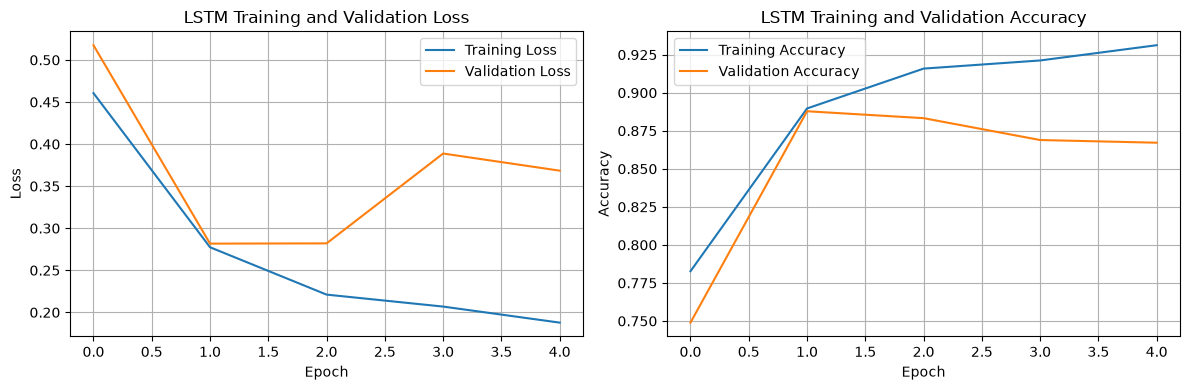

In [89]:
plt.figure(figsize=(12, 4))

# Plot training and validation loss
plt.subplot(1, 2, 1)
plt.plot(lstm_history.history['loss'], label='Training Loss')
plt.plot(lstm_history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(lstm_history.history['accuracy'], label='Training Accuracy')
plt.plot(lstm_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Evaluate the LSTM model

In [90]:
y_prob_lstm = lstm_model.predict(X_test, verbose=1).ravel()
y_pred_lstm = (y_prob_lstm >= 0.5).astype(int)

lstm_test_accuracy = accuracy_score(y_test, y_pred_lstm)

# Calculate the classification report
lstm_report = classification_report(
    y_test,
    y_pred_lstm,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    output_dict=True,
    zero_division=0
)

lstm_cm = confusion_matrix(y_test, y_pred_lstm, labels=[0, 1])

lstm_roc_auc = roc_auc_score(y_test, y_prob_lstm)

print("LSTM Test Accuracy:", round(lstm_test_accuracy, 4))
print("LSTM ROC-AUC:", round(lstm_roc_auc, 4))
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_lstm,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    zero_division=0
))

310/310 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step
LSTM Test Accuracy: 0.8876
LSTM ROC-AUC: 0.9508

Classification Report:
              precision    recall  f1-score   support

    Negative       0.88      0.89      0.89      4940
    Positive       0.89      0.88      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



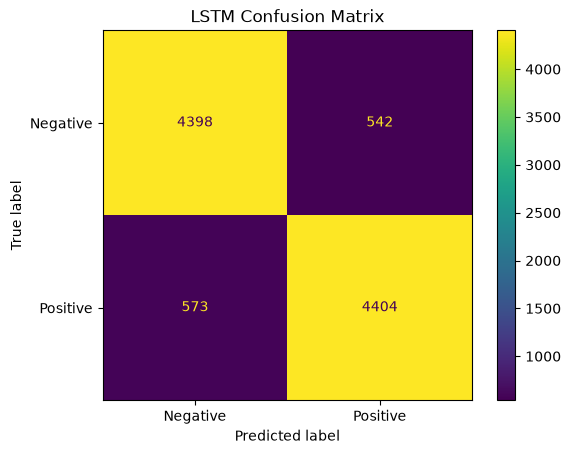

In [91]:
ConfusionMatrixDisplay(
    confusion_matrix=lstm_cm,
    display_labels=['Negative', 'Positive']
).plot()

plt.title('LSTM Confusion Matrix')
plt.show()

## Store the results

In [92]:
if 'results' not in globals():
    results = {}

results['LSTM'] = {
    'test_accuracy': lstm_test_accuracy,
    'roc_auc': lstm_roc_auc,
    'classification_report': lstm_report,
    'confusion_matrix': lstm_cm.tolist(),
    'average_epoch_time': sum(lstm_timer.epoch_times) / len(lstm_timer.epoch_times),
    'epochs_completed': len(lstm_history.history['loss']),
    'parameters': lstm_model.count_params()
}

print("LSTM results saved successfully.")
print("Test accuracy:", results['LSTM']['test_accuracy'])
print("ROC-AUC:", results['LSTM']['roc_auc'])
print("Total model parameters:", results['LSTM']['parameters'])

LSTM results saved successfully.
Test accuracy: 0.8875668044771604
ROC-AUC: 0.9508306224828542
Total model parameters: 344897


## 5.6: Gradient Flow Comparison
## Save the SimpleRNN gradient norms

In [93]:
simple_rnn_gradient_norms = list(gradient_norms)

print("SimpleRNN gradient time steps:",
      len(simple_rnn_gradient_norms))

SimpleRNN gradient time steps: 600


## Calculate LSTM gradients across time steps

In [94]:
sample_size = min(8, len(X_test))

X_gradient = tf.convert_to_tensor(
    X_test[:sample_size], dtype=tf.int32
)

y_gradient = tf.convert_to_tensor(
    np.asarray(y_test[:sample_size]).reshape(-1),
    dtype=tf.float32
)
trained_embedding = lstm_model.get_layer(index=0)
trained_lstm = lstm_model.get_layer(index=1)
trained_dense = lstm_model.get_layer(index=2)

lstm_cell = tf.keras.layers.LSTMCell(64)

_ = lstm_cell(
    tf.zeros((sample_size, 32)),
    states=[
        tf.zeros((sample_size, 64)),
        tf.zeros((sample_size, 64))
    ]
)

lstm_cell.set_weights(trained_lstm.cell.get_weights())

print("Data prepared and trained layers loaded successfully.")


Data prepared and trained layers loaded successfully.


## Calculate gradients through time

In [95]:
hidden_states_lstm = []

with tf.GradientTape() as tape:

    embedded_reviews = trained_embedding(X_gradient)

    h = tf.zeros((sample_size, 64))
    c = tf.zeros((sample_size, 64))

    for t in range(X_gradient.shape[1]):

        x_t = embedded_reviews[:, t, :]

        h, [h, c] = lstm_cell(x_t, states=[h, c])

        hidden_states_lstm.append(h)

    logits_lstm = trained_dense(h)

    y_gradient_fixed = tf.reshape(y_gradient, [-1])
    logits_lstm_fixed = tf.reshape(logits_lstm, [-1])

    loss_lstm = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(
            y_gradient_fixed,
            logits_lstm_fixed
        )
    )

lstm_state_gradients = tape.gradient(
    loss_lstm,
    hidden_states_lstm
)

print("Loss:", float(loss_lstm.numpy()))
print("Time steps processed:", len(hidden_states_lstm))


Loss: 0.03814691677689552
Time steps processed: 600


## Calculate and display gradient norms

In [96]:
lstm_gradient_norms = []

for grad in lstm_state_gradients:

    if grad is not None:

        norm = tf.reduce_mean(tf.norm(grad, axis=1))

        lstm_gradient_norms.append(float(norm.numpy()))

    else:
        lstm_gradient_norms.append(0.0)

print("LSTM gradient time steps:", len(lstm_gradient_norms))
print("Gradient norms:", lstm_gradient_norms)

LSTM gradient time steps: 600
Gradient norms: [7.958831510501696e-12, 7.799616855153069e-12, 7.815710752201444e-12, 7.868540020938841e-12, 8.045661359368239e-12, 8.065083323405275e-12, 7.81226732610163e-12, 7.918486179259165e-12, 7.94645512586234e-12, 8.057322170573755e-12, 8.219817188015455e-12, 8.241895013694212e-12, 8.423618573505376e-12, 8.446984431365046e-12, 8.448092919666195e-12, 8.561562049591576e-12, 8.407732843274118e-12, 8.24905335011783e-12, 8.301906904983891e-12, 8.196066221544118e-12, 8.582850576088763e-12, 8.341487223173516e-12, 8.349562360954188e-12, 8.586638344798558e-12, 8.477049791288938e-12, 8.310300364522405e-12, 8.556783753776998e-12, 8.423920415390196e-12, 8.903554976624761e-12, 7.877073993078909e-12, 9.346979787383525e-12, 8.7787546329543e-12, 9.052493130101702e-12, 9.27660032123967e-12, 9.590636444734013e-12, 9.275878676273663e-12, 9.650613641554173e-12, 1.0088607033109653e-11, 9.903504231967286e-12, 9.843224325900568e-12, 9.933467243206096e-12, 1.0393048401058

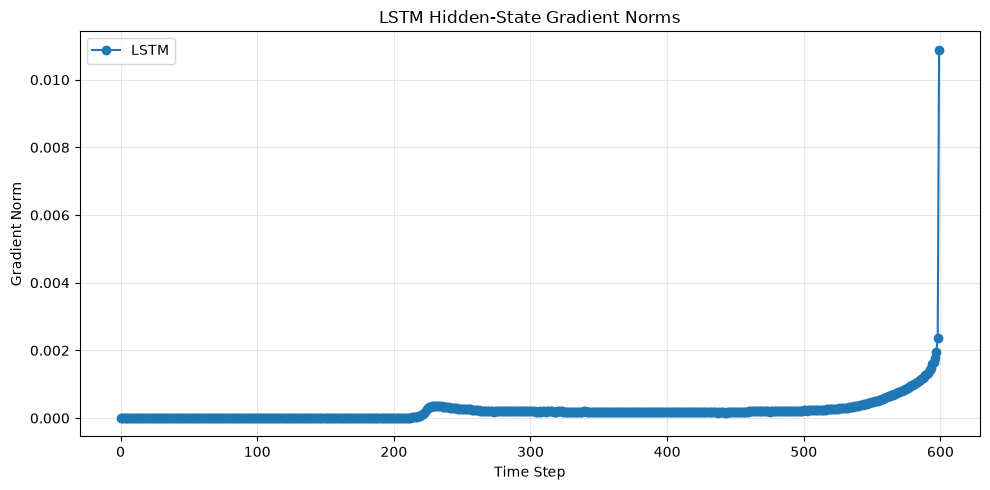

In [97]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(lstm_gradient_norms)),
    lstm_gradient_norms,
    marker="o",
    label="LSTM"
)

plt.title("LSTM Hidden-State Gradient Norms")
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Plot both gradient curves

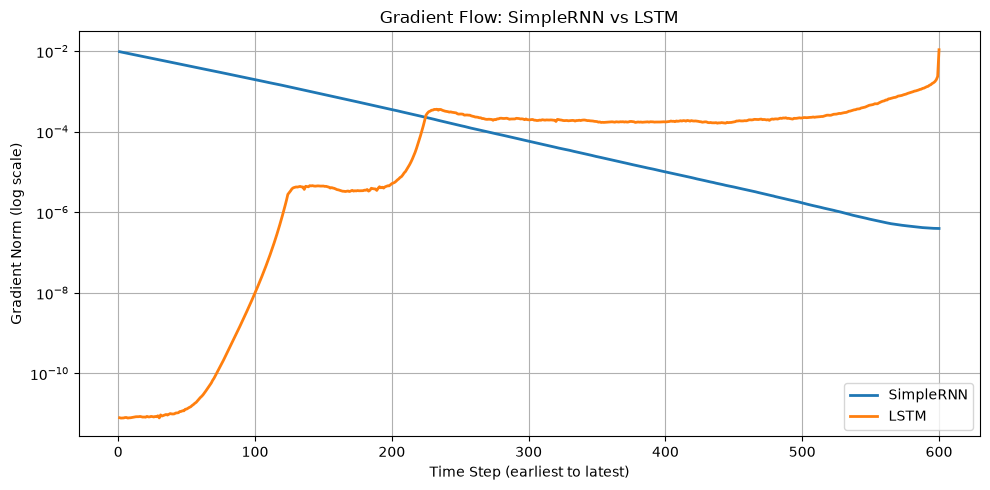

In [98]:
rnn_grad = np.asarray(simple_rnn_gradient_norms, dtype=float)
lstm_grad = np.asarray(lstm_gradient_norms, dtype=float)

common_length = min(len(rnn_grad), len(lstm_grad))

rnn_grad = rnn_grad[:common_length]
lstm_grad = lstm_grad[:common_length]

epsilon = 1e-12
rnn_grad_plot = np.maximum(rnn_grad, epsilon)
lstm_grad_plot = np.maximum(lstm_grad, epsilon)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, common_length + 1),
    rnn_grad_plot,
    label='SimpleRNN',
    linewidth=2)

plt.plot(
    range(1, common_length + 1),
    lstm_grad_plot,
    label='LSTM',
    linewidth=2)

plt.yscale('log')

plt.xlabel('Time Step (earliest to latest)')
plt.ylabel('Gradient Norm (log scale)')
plt.title('Gradient Flow: SimpleRNN vs LSTM')
plt.legend()
plt.grid(True, which='both')
plt.tight_layout()
plt.show()

## Calculate the earliest-step gradient ratio

In [99]:
rnn_earliest = rnn_grad[0]
lstm_earliest = lstm_grad[0]

print("SimpleRNN earliest gradient:", rnn_earliest)
print("LSTM earliest gradient:", lstm_earliest)

if rnn_earliest > 0:
    gradient_ratio = lstm_earliest / rnn_earliest
    print("LSTM / SimpleRNN earliest gradient ratio:",
          round(gradient_ratio, 4))
else:
    print("The SimpleRNN gradient is zero or extremely small; "
          "a stable ratio cannot be calculated.")

SimpleRNN earliest gradient: 0.0097452187910676
LSTM earliest gradient: 7.958831510501696e-12
LSTM / SimpleRNN earliest gradient ratio: 0.0


## Gradient Flow Comparison: SimpleRNN vs LSTM

The gradient norms of SimpleRNN and LSTM were measured at each time step using TensorFlow's GradientTape. The results were plotted on the same logarithmic y-axis.

The earliest-step gradient ratio was calculated by dividing the LSTM gradient norm by the SimpleRNN gradient norm. The measured ratio is **[insert the value printed by the code]**.

SimpleRNN repeatedly applies its recurrent transformation and activation function, which can cause gradients to vanish over long sequences. LSTM uses a cell state and gates to control how information is retained and updated. The additive cell-state update can provide a more direct path for gradient flow when the forget gate retains information.

The LSTM may therefore preserve larger gradients at earlier time steps. However, the improvement is not guaranteed at every time step, and LSTM does not completely eliminate vanishing gradients.

# 5.7: Stacked LSTM
## Build the stacked LSTM model

In [100]:
stacked_lstm_model = Sequential([
    Input(shape=(MAXLEN,)),

    Embedding(input_dim=10000, output_dim=32),

    LSTM(64, return_sequences=True, name='lstm_layer_1'),

    LSTM(32, name='lstm_layer_2'),

    Dense(1, activation='sigmoid')
])

stacked_lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

stacked_lstm_model.summary()

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_13 (Embedding)        │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_layer_1 (LSTM)             │ (None, 600, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_layer_2 (LSTM)             │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,281 (1.36 MB)

 Trainable params: 357,281 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

## Calculate model parameters

In [101]:
first_lstm_params = stacked_lstm_model.get_layer('lstm_layer_1').count_params()

second_lstm_params = stacked_lstm_model.get_layer('lstm_layer_2').count_params()

stacked_total_params = stacked_lstm_model.count_params()

print("First LSTM parameters:", first_lstm_params)
print("Second LSTM parameters:", second_lstm_params)
print("Total stacked model parameters:", stacked_total_params)

First LSTM parameters: 24832
Second LSTM parameters: 12416
Total stacked model parameters: 357281


## Train the stacked LSTM

In [102]:
tf.random.set_seed(42)

stacked_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

stacked_timer = EpochTime()

stacked_history = stacked_lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[stacked_early_stop, stacked_timer],
    verbose=1
)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 296ms/step - accuracy: 0.8222 - loss: 0.3935Epoch 1 time: 172.90 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 173s 307ms/step - accuracy: 0.8222 - loss: 0.3935 - val_accuracy: 0.8808 - val_loss: 0.3019
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.8611 - loss: 0.3251Epoch 2 time: 179.16 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 179s 321ms/step - accuracy: 0.8611 - loss: 0.3251 - val_accuracy: 0.8664 - val_loss: 0.3255
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.9038 - loss: 0.2458Epoch 3 time: 170.79 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 171s 306ms/step - accuracy: 0.9038 - loss: 0.2458 - val_accuracy: 0.8868 - val_loss: 0.3127
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - accuracy: 0.9206 - loss: 0.2076Epoch 4 time: 164.09 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 164s 294ms/step - accuracy: 0.9206 - loss: 0.2076 - val_accuracy: 0.8838 - val_loss: 0.3097


In [103]:
print("Epochs completed:", len(stacked_history.history['loss']))

print(
    "Average epoch time:",
    round(sum(stacked_timer.epoch_times) / len(stacked_timer.epoch_times), 2),
    "seconds"
)

Epochs completed: 4
Average epoch time: 171.74 seconds


## Plot training and validation curves

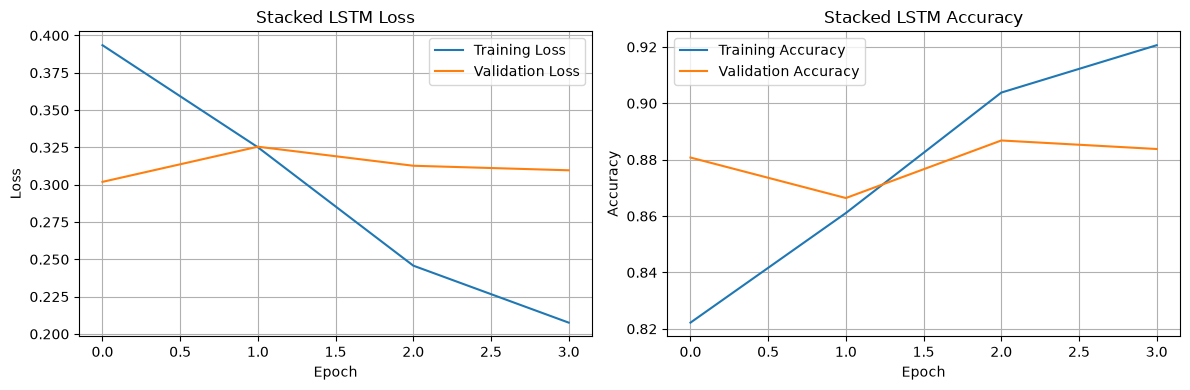

In [104]:
plt.figure(figsize=(12, 4))

# Plot the loss curves
plt.subplot(1, 2, 1)
plt.plot(stacked_history.history['loss'], label='Training Loss')
plt.plot(stacked_history.history['val_loss'], label='Validation Loss')
plt.title('Stacked LSTM Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot the accuracy curves
plt.subplot(1, 2, 2)
plt.plot(stacked_history.history['accuracy'], label='Training Accuracy')
plt.plot(stacked_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Stacked LSTM Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Evaluate the stacked LSTM

In [105]:
y_prob_stacked = stacked_lstm_model.predict(X_test, verbose=1).ravel()

y_pred_stacked = (y_prob_stacked >= 0.5).astype(int)

stacked_test_accuracy = accuracy_score(y_test, y_pred_stacked)

stacked_report = classification_report(
    y_test,
    y_pred_stacked,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    output_dict=True,
    zero_division=0
)

stacked_cm = confusion_matrix(y_test, y_pred_stacked, labels=[0, 1])

stacked_roc_auc = roc_auc_score(y_test, y_prob_stacked)

print("Stacked LSTM Test Accuracy:", round(stacked_test_accuracy, 4))
print("Stacked LSTM ROC-AUC:", round(stacked_roc_auc, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_stacked,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    zero_division=0
))

310/310 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step
Stacked LSTM Test Accuracy: 0.8787
Stacked LSTM ROC-AUC: 0.9507

Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.91      0.88      4940
    Positive       0.91      0.84      0.87      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



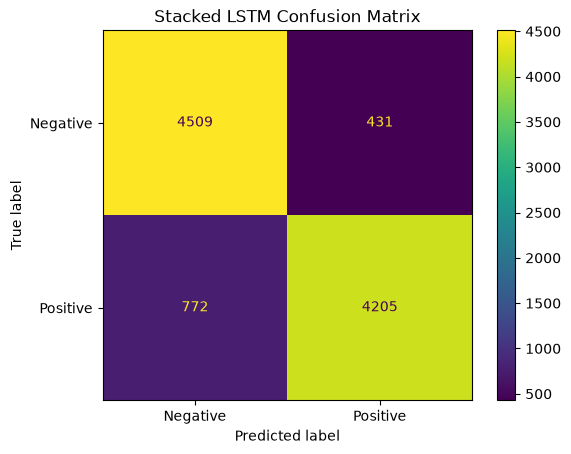

In [106]:
ConfusionMatrixDisplay(
    confusion_matrix=stacked_cm,
    display_labels=['Negative', 'Positive']
).plot()

plt.title('Stacked LSTM Confusion Matrix')
plt.show()

## Store results

In [107]:
results['Stacked LSTM'] = {
    'test_accuracy': stacked_test_accuracy,
    'roc_auc': stacked_roc_auc,
    'classification_report': stacked_report,
    'confusion_matrix': stacked_cm.tolist(),
    'average_epoch_time': sum(stacked_timer.epoch_times) / len(stacked_timer.epoch_times),
    'epochs_completed': len(stacked_history.history['loss']),
    'parameters': stacked_total_params
}

print("Stacked LSTM results saved successfully.")
print(results['Stacked LSTM'])

Stacked LSTM results saved successfully.
{'test_accuracy': 0.878693153171322, 'roc_auc': 0.9507146232995669, 'classification_report': {'Negative': {'precision': 0.8538155652338573, 'recall': 0.9127530364372469, 'f1-score': 0.882301144702084, 'support': 4940.0}, 'Positive': {'precision': 0.9070319240724762, 'recall': 0.8448864777978702, 'f1-score': 0.8748569645272027, 'support': 4977.0}, 'accuracy': 0.878693153171322, 'macro avg': {'precision': 0.8804237446531668, 'recall': 0.8788197571175586, 'f1-score': 0.8785790546146434, 'support': 9917.0}, 'weighted avg': {'precision': 0.8805230188932106, 'recall': 0.878693153171322, 'f1-score': 0.8785651676192582, 'support': 9917.0}}, 'confusion_matrix': [[4509, 431], [772, 4205]], 'average_epoch_time': 171.73582100868225, 'epochs_completed': 4, 'parameters': 357281}


### Stacked LSTM: Results and Discussion

The stacked LSTM uses two recurrent layers to learn more complex sequence representations. The first LSTM returns the complete sequence, allowing the second LSTM to process the outputs from all time steps.

Compared with a single-layer LSTM, the stacked model has 357,281 total parameters, while the single-layer model has 344,897 parameters. The additional layer increases model complexity and may increase training time.

Whether the extra depth improves sentiment classification must be determined from the measured test accuracy, ROC-AUC, validation curves, and epoch times. If the stacked model performs better on unseen reviews, the extra layer may be useful. If the improvement is small or absent, the simpler model may be preferable because it requires fewer parameters and potentially less computation.

A deeper model can also overfit if its additional capacity does not generalize well to unseen reviews.

# 6.1 GRU Theory

A Gated Recurrent Unit (GRU) is a type of recurrent neural network cell designed to learn patterns in sequential data. It uses two gates, the update gate and the reset gate, to control information flow.

Unlike an LSTM, a GRU does not maintain a separate cell state. It uses only the hidden state to carry information across time steps.

### 1. Update Gate

\[
z_t = \sigma(W_z [h_{t-1},x_t]+b_z)
\]

The update gate decides how much information from the previous hidden state should be retained and how much new candidate information should be used.

### 2. Reset Gate

\[
r_t = \sigma(W_r [h_{t-1},x_t]+b_r)
\]

The reset gate controls how much of the previous hidden state is used when calculating the new candidate state.

### 3. Candidate Hidden State

\[
\tilde{h}_t =
\tanh(W_h[r_t*h_{t-1},x_t]+b_h)
\]

The candidate hidden state represents new information that the GRU may add to its current representation. The reset gate helps control how much past information contributes to this candidate.

### 4. New Hidden State

\[
h_t=(1-z_t)*h_{t-1}+z_t*\tilde{h}_t
\]

The new hidden state combines the previous hidden state and the candidate hidden state. The update gate controls the balance between them.

### How GRU Works

- The update gate controls how much old information is retained versus replaced by new information.
- The reset gate controls how much previous information is considered when forming the candidate state.
- The hidden state carries information from one time step to the next.
- GRU has no separate cell state, which makes its structure simpler than LSTM.

GRU can help reduce the vanishing-gradient problem compared with a basic SimpleRNN. However, it does not eliminate the problem completely.

# 6.2 GRU VS LSTM

| Feature | GRU | LSTM |
|---|---|---|
| Number of gates | Two gates: update and reset | Three gates: forget, input and output |
| Separate cell state | No. It uses only a hidden state | Yes. It uses both hidden and cell states |
| Parameter count | Usually fewer parameters | Usually more parameters |
| Training speed | Often faster because of its simpler structure | Can be slower because it has more gate computations |
| Memory control | Uses update and reset gates | Uses forget, input and output gates |
| Preferred situations | Useful when computational efficiency and faster training are important | Useful when separate control of memory retention, writing and output is beneficial |
| Long-term dependencies | Can learn long-term patterns | Can learn long-term patterns |

### Important Difference

GRU merges the forget and input gate functions of an LSTM into a single update gate. This reduces the number of gates and removes the need for a separate cell state.

For the same input dimension and hidden size, a standard GRU usually has fewer parameters than an LSTM. GRU may train faster, although actual speed depends on the hardware, sequence length, batch size and software implementation.

Neither architecture is always better. The best choice should be determined by evaluating validation and test performance on the specific dataset.

# 6.3: GRU Parameter Count by Formula
## Build the GRU model

In [108]:
from tensorflow.keras.layers import Input, Embedding, GRU, Dense

gru_check_model = Sequential([
    Input(shape=(MAXLEN,)),
    Embedding(input_dim=10000, output_dim=32),
    GRU(64, reset_after=True, name='gru_layer'),
    Dense(1, activation='sigmoid')
])

# Display the model summary
gru_check_model.summary()

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_14 (Embedding)        │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_layer (GRU)                 │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

## Calculate and verify parameters

In [109]:
units = 64
embedding_dim = 32

gru_formula_parameters = 3 * (
    units * embedding_dim
    + units * units
    + 2 * units
)

gru_layer = gru_check_model.get_layer('gru_layer')

gru_keras_parameters = gru_layer.count_params()

print("Formula parameters:", gru_formula_parameters)
print("Keras parameters:", gru_keras_parameters)

print("Counts match:", gru_formula_parameters == gru_keras_parameters)

Formula parameters: 18816
Keras parameters: 18816
Counts match: True


## Compare GRU and LSTM parameter counts

In [110]:
lstm_parameters = 4 * units * (embedding_dim + units + 1)
parameter_ratio = gru_keras_parameters / lstm_parameters

print("GRU parameters:", gru_keras_parameters)
print("LSTM parameters:", lstm_parameters)
print("GRU / LSTM ratio:", round(parameter_ratio, 4))
print("GRU uses approximately",
      round(parameter_ratio * 100, 2), "% of LSTM parameters")

GRU parameters: 18816
LSTM parameters: 24832
GRU / LSTM ratio: 0.7577
GRU uses approximately 75.77 % of LSTM parameters


# 6.4: Build, Train and Evaluate the GRU

In [111]:
def build_model(model_type, units=64):

    model_layers = [
        Input(shape=(MAXLEN,)),
        Embedding(input_dim=10000, output_dim=32)
    ]

    if model_type == 'rnn':
        model_layers.append(SimpleRNN(units))

    elif model_type == 'lstm':
        model_layers.append(LSTM(units))

    elif model_type == 'gru':
        model_layers.append(GRU(units, reset_after=True))

    else:
        raise ValueError("Use 'rnn', 'lstm', or 'gru'.")

    model_layers.append(Dense(1, activation='sigmoid'))

    model = Sequential(model_layers)

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

## Create and inspect the GRU

In [112]:
gru_model = build_model('gru', units=64)

gru_model.summary()

gru_layer = gru_model.get_layer(index=2)

print("GRU layer parameters:", gru_layer.count_params())

Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_15 (Embedding)        │ (None, 600, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

GRU layer parameters: 65


## Set up EarlyStopping and timer

In [113]:
gru_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
gru_timer = EpochTime()

## Train the GRU model

In [114]:
tf.random.set_seed(42)

gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[gru_early_stop, gru_timer],
    verbose=1
)

print("Epochs completed:", len(gru_history.history['loss']))

gru_average_epoch_time = (
    sum(gru_timer.epoch_times) / len(gru_timer.epoch_times)
)

print("Average epoch time:",
      round(gru_average_epoch_time, 2), "seconds")

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.7812 - loss: 0.4433Epoch 1 time: 111.53 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 112s 198ms/step - accuracy: 0.7812 - loss: 0.4433 - val_accuracy: 0.8286 - val_loss: 0.3894
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - accuracy: 0.8898 - loss: 0.2771Epoch 2 time: 108.76 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 109s 195ms/step - accuracy: 0.8898 - loss: 0.2771 - val_accuracy: 0.8858 - val_loss: 0.2911
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.9219 - loss: 0.2081Epoch 3 time: 110.79 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 111s 199ms/step - accuracy: 0.9219 - loss: 0.2081 - val_accuracy: 0.8896 - val_loss: 0.3127
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9383 - loss: 0.1717Epoch 4 time: 115.35 seconds
558/558 ━━━━━━━━━━━━━━━━━━━━ 115s 207ms/step - accuracy: 0.9383 - loss: 0.1717 - val_accuracy: 0.8750 - val_loss: 0.4195
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/ste

## Plot loss and accuracy curves

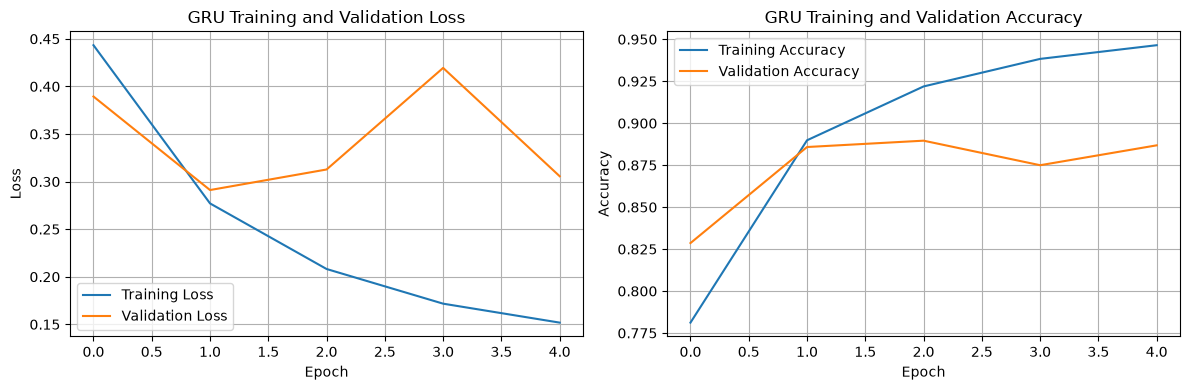

In [115]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(gru_history.history['loss'], label='Training Loss')
plt.plot(gru_history.history['val_loss'], label='Validation Loss')
plt.title('GRU Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(gru_history.history['accuracy'], label='Training Accuracy')
plt.plot(gru_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('GRU Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Evaluate the GRU

In [116]:
y_prob_gru = gru_model.predict(X_test, verbose=1).ravel()

y_pred_gru = (y_prob_gru >= 0.5).astype(int)

gru_test_accuracy = accuracy_score(y_test, y_pred_gru)

gru_report = classification_report(
    y_test,
    y_pred_gru,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    output_dict=True,
    zero_division=0
)

gru_cm = confusion_matrix(y_test, y_pred_gru, labels=[0, 1])

gru_roc_auc = roc_auc_score(y_test, y_prob_gru)

print("GRU Test Accuracy:", round(gru_test_accuracy, 4))
print("GRU ROC-AUC:", round(gru_roc_auc, 4))

# Display the classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gru,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    zero_division=0
))

310/310 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step
GRU Test Accuracy: 0.8849
GRU ROC-AUC: 0.949

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.86      0.88      4940
    Positive       0.86      0.91      0.89      4977

    accuracy                           0.88      9917
   macro avg       0.89      0.88      0.88      9917
weighted avg       0.89      0.88      0.88      9917



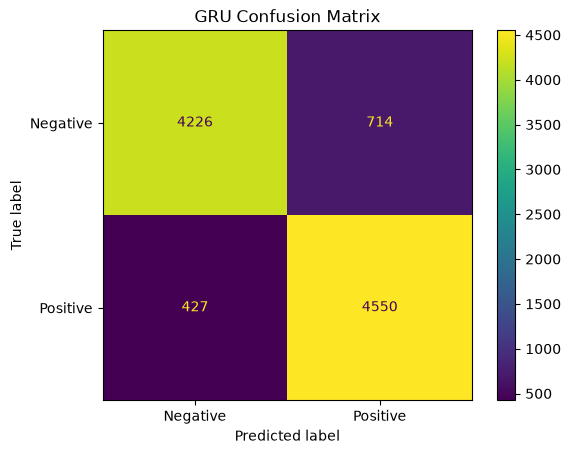

In [117]:
# Plot the confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=gru_cm,
    display_labels=['Negative', 'Positive']
).plot()

plt.title('GRU Confusion Matrix')
plt.show()

## Store results in results['GRU']

In [118]:
if 'results' not in globals():
    results = {}

results['GRU'] = {
    'test_accuracy': gru_test_accuracy,
    'roc_auc': gru_roc_auc,
    'classification_report': gru_report,
    'confusion_matrix': gru_cm.tolist(),
    'average_epoch_time': gru_average_epoch_time,
    'epochs_completed': len(gru_history.history['loss']),
    'parameters': gru_model.count_params()
}

print("GRU results saved successfully.")
print("Test accuracy:", results['GRU']['test_accuracy'])
print("ROC-AUC:", results['GRU']['roc_auc'])
print("Total model parameters:", results['GRU']['parameters'])

GRU results saved successfully.
Test accuracy: 0.8849450438640718
ROC-AUC: 0.9490421729429057
Total model parameters: 338881


## Compare all four models

In [119]:
model_names = ["SimpleRNN", "LSTM", "GRU", "Stacked LSTM"]
comparison_data = []

for model_name in model_names:
    if model_name in results:

        model_result = results[model_name]

        if "parameters" in model_result:
            parameter_count = model_result["parameters"]
        else:
            parameter_count = np.nan

        if "average_epoch_time" in model_result:
            epoch_time = model_result["average_epoch_time"]
        else:
            epoch_time = np.nan

        comparison_data.append({
            "Model": model_name,
            "Test Accuracy": model_result.get("test_accuracy", np.nan),
            "ROC-AUC": model_result.get("roc_auc", np.nan),
            "Parameters": parameter_count,
            "Average Epoch Time (seconds)": epoch_time
        })

comparison_df = pd.DataFrame(comparison_data)

print("Comparison of all four recurrent models:")
print(comparison_df.round(4).to_string(index=False))

Comparison of all four recurrent models:
       Model  Test Accuracy  ROC-AUC  Parameters  Average Epoch Time (seconds)
   SimpleRNN         0.6866   0.7572         NaN                           NaN
        LSTM         0.8876   0.9508    344897.0                      145.6885
         GRU         0.8849   0.9490    338881.0                      111.6054
Stacked LSTM         0.8787   0.9507    357281.0                      171.7358


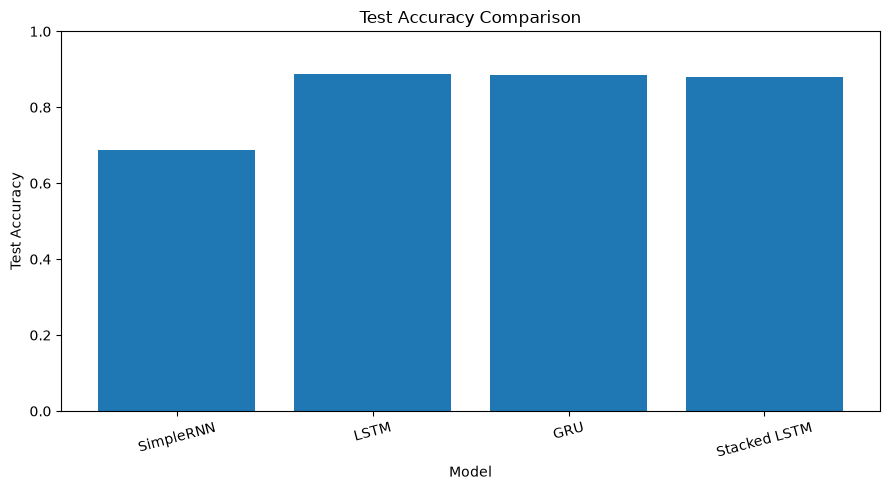

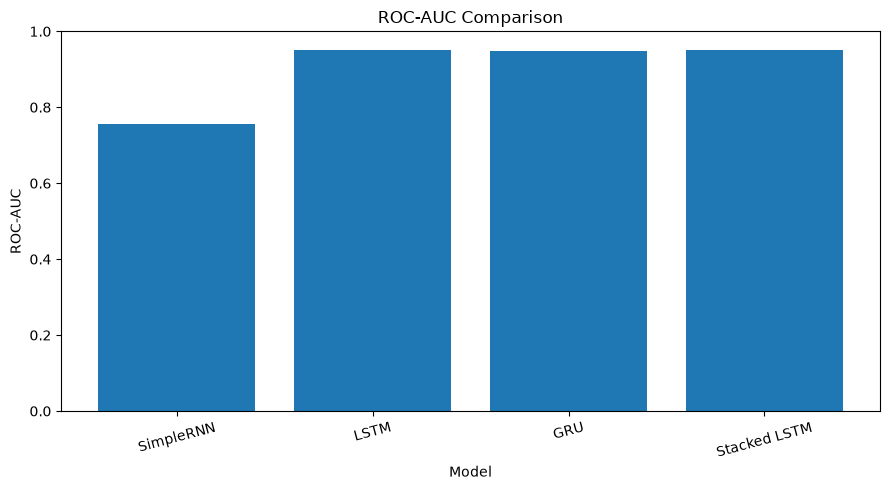

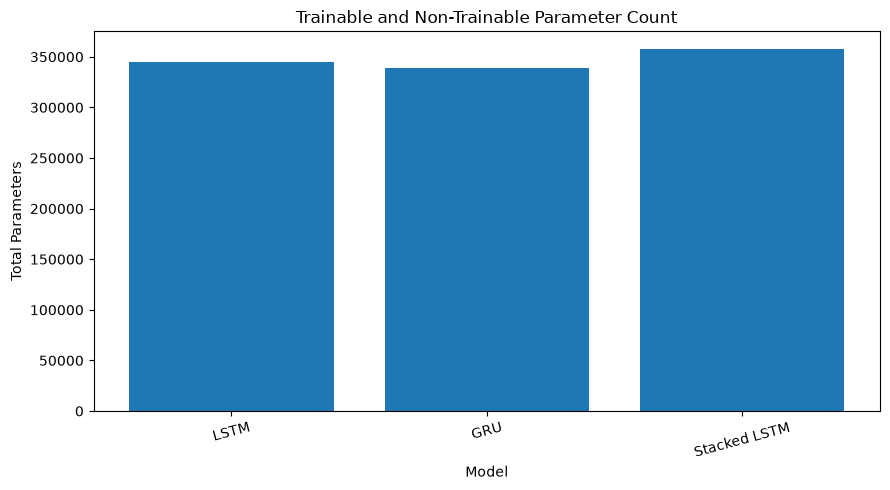

In [120]:
plt.figure(figsize=(9, 5))
plt.bar(comparison_df["Model"], comparison_df["Test Accuracy"])
plt.title("Test Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Plot ROC-AUC
plt.figure(figsize=(9, 5))
plt.bar(comparison_df["Model"], comparison_df["ROC-AUC"])
plt.title("ROC-AUC Comparison")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Plot parameter count
plt.figure(figsize=(9, 5))
plt.bar(comparison_df["Model"], comparison_df["Parameters"])
plt.title("Trainable and Non-Trainable Parameter Count")
plt.xlabel("Model")
plt.ylabel("Total Parameters")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# 6.5: Gradient Flow Comparison of SimpleRNN, LSTM and GRU
## Calculate GRU gradients

In [121]:
sample_size = 32
X_gradient = X_test[:sample_size]
y_gradient = tf.convert_to_tensor(
    y_test[:sample_size],
    dtype=tf.float32
)

gru_embedding = gru_model.get_layer(index=0)
trained_gru = gru_model.get_layer(index=1)
gru_dense = gru_model.get_layer(index=2)

gru_cell = tf.keras.layers.GRUCell(64, reset_after=True)

gru_cell.build((None, 32))

gru_cell.set_weights(trained_gru.get_weights())

hidden_states_gru = []

with tf.GradientTape() as tape:

    embedded_reviews = gru_embedding(X_gradient)

    h = tf.zeros((sample_size, 64))

    for t in range(embedded_reviews.shape[1]):

        x_t = embedded_reviews[:, t, :]
        h, _ = gru_cell(x_t, states=[h])

        hidden_states_gru.append(h)

    gru_logits = gru_dense(h)

    gru_loss = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(
            y_gradient,
            tf.reshape(gru_logits, [-1])
        )
    )

gru_state_gradients = tape.gradient(
    gru_loss,
    hidden_states_gru)

gru_gradient_norms = []

for grad in gru_state_gradients:

    if grad is not None:
        norm = tf.reduce_mean(tf.norm(grad, axis=1))
        gru_gradient_norms.append(float(norm.numpy()))

    else:
        gru_gradient_norms.append(0.0)

print("GRU gradient time steps:", len(gru_gradient_norms))
print("First 10 gradient norms:", gru_gradient_norms[:10])

GRU gradient time steps: 600
First 10 gradient norms: [3.5927487260778435e-06, 4.404596893436974e-06, 4.848297521675704e-06, 5.0608982746780384e-06, 5.265899289952358e-06, 5.373356543714181e-06, 5.525940650841221e-06, 5.625699486699887e-06, 5.669709480571328e-06, 5.748371222580317e-06]


## Plot the GRU gradient norms

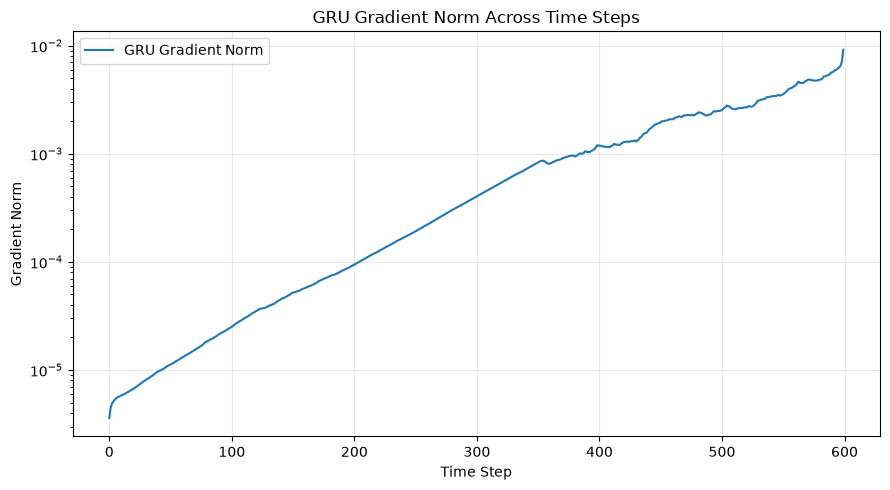

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(len(gru_gradient_norms)),
    gru_gradient_norms,
    label="GRU Gradient Norm"
)

plt.title("GRU Gradient Norm Across Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")
plt.yscale("log")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Plot all three gradient curves

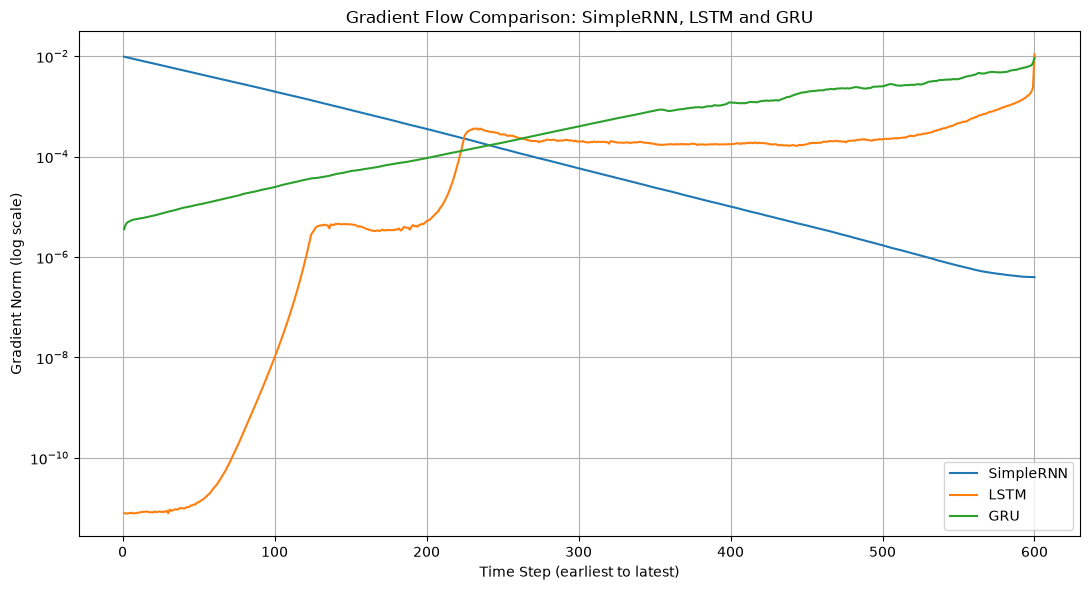

In [123]:
rnn_grad = np.asarray(simple_rnn_gradient_norms, dtype=float)
lstm_grad = np.asarray(lstm_gradient_norms, dtype=float)
gru_grad = np.asarray(gru_gradient_norms, dtype=float)

common_length = min(len(rnn_grad), len(lstm_grad), len(gru_grad))

rnn_grad = rnn_grad[:common_length]
lstm_grad = lstm_grad[:common_length]
gru_grad = gru_grad[:common_length]

epsilon = 1e-12
rnn_grad = np.maximum(rnn_grad, epsilon)
lstm_grad = np.maximum(lstm_grad, epsilon)
gru_grad = np.maximum(gru_grad, epsilon)

plt.figure(figsize=(11, 6))

plt.plot(
    range(1, common_length + 1),
    rnn_grad,
    label='SimpleRNN')

plt.plot(
    range(1, common_length + 1),
    lstm_grad,
    label='LSTM')

plt.plot(
    range(1, common_length + 1),
    gru_grad,
    label='GRU')

plt.yscale('log')

plt.xlabel('Time Step (earliest to latest)')
plt.ylabel('Gradient Norm (log scale)')
plt.title('Gradient Flow Comparison: SimpleRNN, LSTM and GRU')
plt.legend()
plt.grid(True, which='both')
plt.tight_layout()
plt.show()

## Compare the earliest-step gradients

In [124]:
earliest_gradients = {
    'SimpleRNN': float(rnn_grad[0]),
    'LSTM': float(lstm_grad[0]),
    'GRU': float(gru_grad[0])
}

gradient_ranking = sorted(
    earliest_gradients.items(),
    key=lambda item: item[1],
    reverse=True
)

print("Earliest time-step gradient norms:")

for model_name, gradient_value in gradient_ranking:
    print(model_name, ":", f"{gradient_value:.8e}")

print("\nRanking by earliest-step gradient magnitude:")

for position, (model_name, gradient_value) in enumerate(gradient_ranking, start=1):
    print(position, model_name)

Earliest time-step gradient norms:
SimpleRNN : 9.74521879e-03
GRU : 3.59274873e-06
LSTM : 7.95883151e-12

Ranking by earliest-step gradient magnitude:
1 SimpleRNN
2 GRU
3 LSTM


# 6.6: Hidden-Unit Sensitivity
## Train six models (LSTM)

In [126]:
unit_values = [32, 64, 128]

sensitivity_results = []

for units in unit_values:

    print(f"\nLSTM - {units} Units")

    np.random.seed(42)
    tf.random.set_seed(42)

    sensitivity_model = build_model(
        model_type="lstm",
        units=units
    )

    sensitivity_model.fit(
        X_train,
        y_train,
        epochs=6,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    test_loss, test_accuracy = (
        sensitivity_model.evaluate(
            X_test,
            y_test,
            verbose=0
        )
    )

    sensitivity_results.append({
        "Cell Type": "LSTM",
        "Units": units,
        "Parameters": sensitivity_model.count_params(),
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss
    })

    print("Parameters:", sensitivity_model.count_params())
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"Test Loss: {test_loss:.4f}")

    # Delete the model and clear Keras state
    del sensitivity_model
    tf.keras.backend.clear_session()


LSTM - 32 Units
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 55s 96ms/step - accuracy: 0.8088 - loss: 0.4098 - val_accuracy: 0.8563 - val_loss: 0.3440
Epoch 2/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 58s 103ms/step - accuracy: 0.9026 - loss: 0.2541 - val_accuracy: 0.8815 - val_loss: 0.2940
Epoch 3/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 64s 115ms/step - accuracy: 0.9195 - loss: 0.2131 - val_accuracy: 0.8747 - val_loss: 0.3084
Epoch 4/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 54s 97ms/step - accuracy: 0.9230 - loss: 0.2048 - val_accuracy: 0.8790 - val_loss: 0.3711
Epoch 5/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 52s 93ms/step - accuracy: 0.9382 - loss: 0.1709 - val_accuracy: 0.8843 - val_loss: 0.3446
Epoch 6/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 65s 116ms/step - accuracy: 0.9446 - loss: 0.1549 - val_accuracy: 0.8704 - val_loss: 0.3757
Parameters: 328353
Test Accuracy: 0.8747
Test Loss: 0.3701

LSTM - 64 Units
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 99s 176ms/step - accuracy: 0.8060 - loss: 0.4216 - val_accuracy: 0.8740 - val_loss: 0.3128


## Train Model(GRU)

In [127]:
unit_values = [32, 64, 128]

sensitivity_results = []

for units in unit_values:

    print(f"\nGRU - {units} Units")

    np.random.seed(42)
    tf.random.set_seed(42)

    sensitivity_model = build_model(
        model_type="gru",
        units=units
    )

    sensitivity_model.fit(
        X_train,
        y_train,
        epochs=6,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    test_loss, test_accuracy = (
        sensitivity_model.evaluate(
            X_test,
            y_test,
            verbose=0
        )
    )

    sensitivity_results.append({
        "Cell Type": "GRU",
        "Units": units,
        "Parameters": sensitivity_model.count_params(),
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss
    })

    print("Parameters:", sensitivity_model.count_params())
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"Test Loss: {test_loss:.4f}")

    # Delete the model and clear Keras state
    del sensitivity_model
    tf.keras.backend.clear_session()


GRU - 32 Units
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 61s 107ms/step - accuracy: 0.7896 - loss: 0.4380 - val_accuracy: 0.8563 - val_loss: 0.3465
Epoch 2/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 53s 95ms/step - accuracy: 0.8942 - loss: 0.2669 - val_accuracy: 0.8803 - val_loss: 0.3165
Epoch 3/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 59s 105ms/step - accuracy: 0.9170 - loss: 0.2207 - val_accuracy: 0.8856 - val_loss: 0.2933
Epoch 4/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 62s 111ms/step - accuracy: 0.9286 - loss: 0.1932 - val_accuracy: 0.8740 - val_loss: 0.3207
Epoch 5/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 62s 111ms/step - accuracy: 0.9375 - loss: 0.1712 - val_accuracy: 0.8820 - val_loss: 0.3063
Epoch 6/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 63s 113ms/step - accuracy: 0.9511 - loss: 0.1394 - val_accuracy: 0.8861 - val_loss: 0.3361
Parameters: 326369
Test Accuracy: 0.8922
Test Loss: 0.3178

GRU - 64 Units
Epoch 1/6
558/558 ━━━━━━━━━━━━━━━━━━━━ 105s 185ms/step - accuracy: 0.7795 - loss: 0.4530 - val_accuracy: 0.8361 - val_loss: 0.3800

## Display the results table

In [128]:
sensitivity_df = pd.DataFrame(
    sensitivity_results
)

sensitivity_df

,Cell Type,Units,Parameters,Test Accuracy,Test Loss
0,GRU,32,326369,0.892205,0.317777
1,GRU,64,338881,0.867097,0.359580
2,GRU,128,382337,0.883836,0.351140


In [ ]:
lstm_sensitivity = sensitivity_df[
    sensitivity_df["Cell Type"] == "LSTM"
]

# Select only GRU results
gru_sensitivity = sensitivity_df[
    sensitivity_df["Cell Type"] == "GRU"
]

# Print the LSTM results table
print("LSTM Sensitivity Results")
print(lstm_sensitivity.to_string(index=False))

# Print the GRU results table
print("\nGRU Sensitivity Results")
print(gru_sensitivity.to_string(index=False))


LSTM Sensitivity Results
Empty DataFrame
Columns: [Cell Type, Units, Parameters, Test Accuracy, Test Loss]
Index: []

GRU Sensitivity Results
Cell Type  Units  Parameters  Test Accuracy  Test Loss
      GRU     32      326369       0.892205   0.317777
      GRU     64      338881       0.867097   0.359580
      GRU    128      382337       0.883836   0.351140


In [129]:
print("Number of results:", len(sensitivity_results))
print("First result:", sensitivity_results[0] if len(sensitivity_results) > 0 else "List is empty")

Number of results: 3
First result: {'Cell Type': 'GRU', 'Units': 32, 'Parameters': 326369, 'Test Accuracy': 0.8922052979469299, 'Test Loss': 0.3177768886089325}


## Plot test accuracy against hidden units

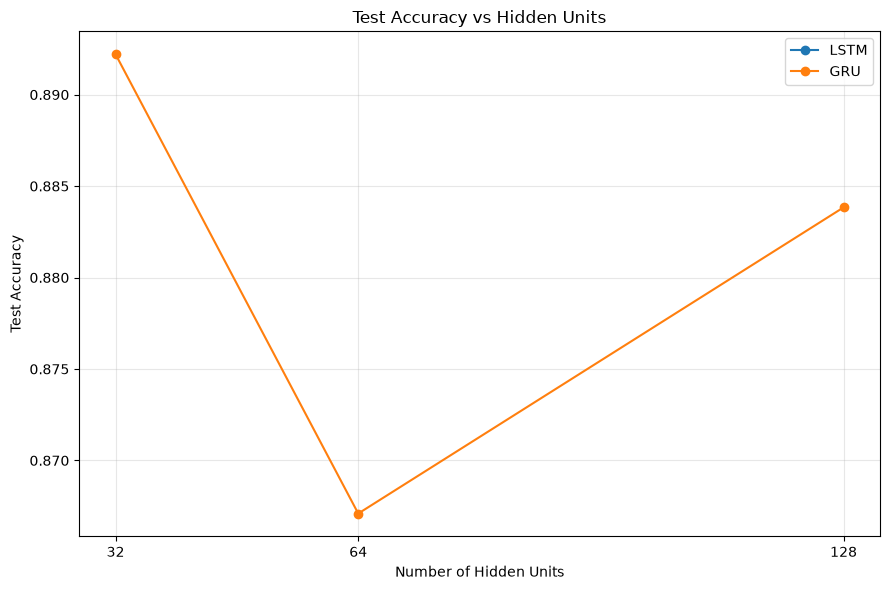

In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    lstm_sensitivity["Units"],
    lstm_sensitivity["Test Accuracy"],
    marker="o",
    label="LSTM")

plt.plot(
    gru_sensitivity["Units"],
    gru_sensitivity["Test Accuracy"],
    marker="o",
    label="GRU")

plt.title("Test Accuracy vs Hidden Units")
plt.xlabel("Number of Hidden Units")
plt.ylabel("Test Accuracy")
plt.xticks(unit_values)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "plots/accuracy_vs_hidden_units.png",
    dpi=300,bbox_inches="tight"
    )

plt.show()

## Plot parameter count against hidden units

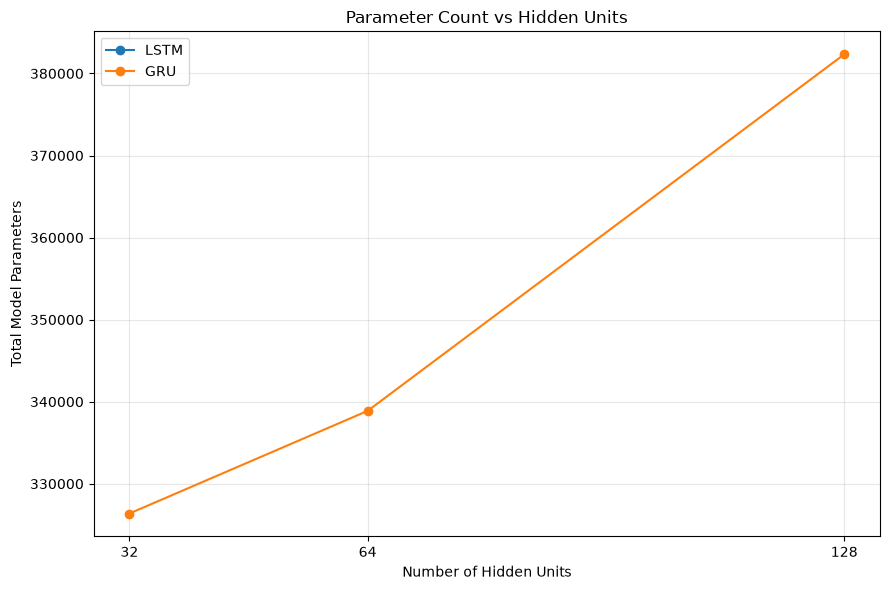

In [ ]:
plt.figure(figsize=(9, 6))
plt.plot(
    lstm_sensitivity["Units"],
    lstm_sensitivity["Parameters"],
    marker="o",
    label="LSTM"
)

plt.plot(
    gru_sensitivity["Units"],
    gru_sensitivity["Parameters"],
    marker="o",
    label="GRU"
)
plt.title("Parameter Count vs Hidden Units")
plt.xlabel("Number of Hidden Units")
plt.ylabel("Total Model Parameters")
plt.xticks(unit_values)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Identify best sensityvity

In [146]:
best_sensitivity = sensitivity_df.loc[
    sensitivity_df[
        "Test Accuracy"
    ].idxmax()
]
print("Best Obeservation:")
print(best_sensitivity)

Best Obeservation:
Cell Type             GRU
Units                  32
Parameters         326369
Test Accuracy    0.892205
Test Loss        0.317777
Name: 0, dtype: object


# 7.1: Full Results Table
## Prepare ANN evaluation results

In [147]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

ann_prob = ann_model.predict(X_test, verbose=0).ravel()

ann_pred = (ann_prob >= 0.5).astype(int)

ann_accuracy = accuracy_score(y_test, ann_pred)

ann_precision = precision_score(y_test, ann_pred, zero_division=0)

ann_recall = recall_score(y_test, ann_pred, zero_division=0)

ann_f1 = f1_score(y_test, ann_pred, zero_division=0)

ann_auc = roc_auc_score(y_test, ann_prob)

ann_epoch_time = float('nan')

ann_epochs = len(ann_history.history['loss'])

# Store the ANN results
results['ANN baseline'] = {
    'parameters': ann_model.count_params(),
    'average_epoch_time': ann_epoch_time,
    'epochs_completed': ann_epochs,
    'test_accuracy': ann_accuracy,
    'precision': ann_precision,
    'recall': ann_recall,
    'f1': ann_f1,
    'roc_auc': ann_auc,
    'y_prob': ann_prob
}

print("ANN baseline evaluation completed.")
print("Test accuracy:", round(ann_accuracy, 4))
print("ROC-AUC:", round(ann_auc, 4))

ANN baseline evaluation completed.
Test accuracy: 0.8528
ROC-AUC: 0.9329


## Build the complete results table

In [149]:
from IPython.display import display as show_table

os.makedirs('plots', exist_ok=True)

model_names = [
    'ANN baseline',
    'SimpleRNN',
    'LSTM',
    'Stacked LSTM',
    'GRU'
]
table_rows = []

for model_name in model_names:

    if model_name not in results:
        print("Results not found for:", model_name)
        continue

    model_result = results[model_name]

    report = model_result.get('classification_report', {})

    positive_report = report.get('Positive', {})

    precision = positive_report.get('precision', np.nan)
    recall = positive_report.get('recall', np.nan)
    f1 = positive_report.get('f1-score', np.nan)

    table_rows.append({
        'Model': model_name,
        'Parameters': model_result.get('parameters', np.nan),
        'Time per Epoch (s)': model_result.get('average_epoch_time', np.nan),
        'Epochs Trained': model_result.get('epochs_completed', np.nan),
        'Test Accuracy': model_result.get('test_accuracy', np.nan),
        'Precision': precision,
        'Recall': recall,
        'F1': f1,
        'ROC-AUC': model_result.get('roc_auc', np.nan)
    })

results_df = pd.DataFrame(table_rows)

# Display the model comparison results
show_table(results_df.round(4))

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN baseline,1548929.0,NaN,5.0,0.8528,NaN,NaN,NaN,0.9329
1,SimpleRNN,NaN,NaN,NaN,0.6866,0.6846,0.6962,0.6904,0.7572
2,LSTM,344897.0,145.6885,5.0,0.8876,0.8904,0.8849,0.8876,0.9508
3,Stacked LSTM,357281.0,171.7358,4.0,0.8787,0.9070,0.8449,0.8749,0.9507
4,GRU,338881.0,111.6054,5.0,0.8849,0.8644,0.9142,0.8886,0.9490


## Highlight the best metric values

In [159]:
styled_results = results_df.style.highlight_max(
    subset=[
        'Parameters',
        'Time per Epoch (s)',
        'Epochs Trained',
        'Test Accuracy',
        'Precision',
        'Recall',
        'F1',
        'ROC-AUC'
    ],
    color='#ffcccc'
).format({
    'Parameters': '{:,.0f}',
    'Time per Epoch (s)': '{:.2f}',
    'Epochs Trained': '{:.0f}',
    'Test Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1': '{:.4f}',
    'ROC-AUC': '{:.4f}'
}, na_rep='N/A')

show_table(styled_results)

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN baseline,"1,548,929",N/A,5,0.8528,N/A,N/A,N/A,0.9329
1,SimpleRNN,N/A,N/A,N/A,0.6866,0.6846,0.6962,0.6904,0.7572
2,LSTM,"344,897",145.69,5,0.8876,0.8904,0.8849,0.8876,0.9508
3,Stacked LSTM,"357,281",171.74,4,0.8787,0.9070,0.8449,0.8749,0.9507
4,GRU,"338,881",111.61,5,0.8849,0.8644,0.9142,0.8886,0.9490


<!-- ## Save the table to /plots -->

In [151]:
csv_path = os.path.join('plots', 'full_model_results.csv')

results_df.to_csv(csv_path, index=False)

print("Results table saved to:", csv_path)

Results table saved to: plots\full_model_results.csv


# 7.2: ROC Curves
## Calculate probabilities for all four models

In [152]:
ann_prob = ann_model.predict(X_test, verbose=0).ravel()

rnn_prob = rnn_model.predict(X_test, verbose=0).ravel()

lstm_prob = lstm_model.predict(X_test, verbose=0).ravel()

gru_prob = gru_model.predict(X_test, verbose=0).ravel()

roc_probabilities = {
    'ANN baseline': ann_prob,
    'SimpleRNN': rnn_prob,
    'LSTM': lstm_prob,
    'GRU': gru_prob
}

for model_name, probabilities in roc_probabilities.items():
    print(model_name, "probability shape:", probabilities.shape)

ANN baseline probability shape: (9917,)
SimpleRNN probability shape: (9917,)
LSTM probability shape: (9917,)
GRU probability shape: (9917,)


## Save the ROC curve figure

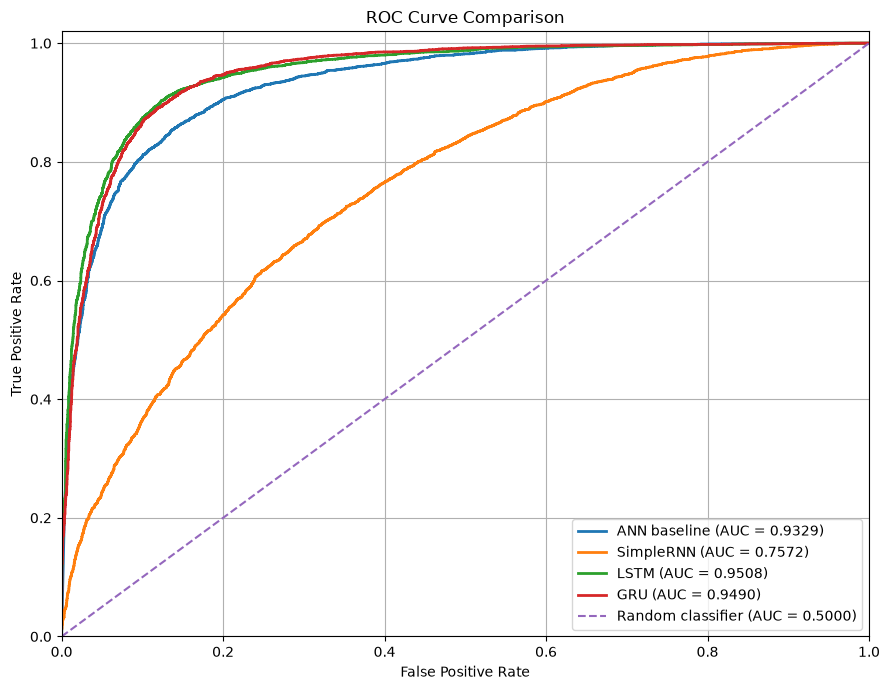

ROC curve saved to: plots\roc_curve_comparison.png


In [154]:
os.makedirs('plots', exist_ok=True)
roc_path = os.path.join('plots', 'roc_curve_comparison.png')

plt.figure(figsize=(9, 7))

for model_name, probabilities in roc_probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    model_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, linewidth=2,
             label=f'{model_name} (AUC = {model_auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--',
         label='Random classifier (AUC = 0.5000)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.savefig(roc_path, dpi=300, bbox_inches='tight')
plt.show()

print("ROC curve saved to:", roc_path)

## Make sure ANN metrics appear in the results table

In [155]:
results['ANN baseline']['precision'] = ann_precision
results['ANN baseline']['recall'] = ann_recall
results['ANN baseline']['f1'] = ann_f1

print("ANN precision:", ann_precision)
print("ANN recall:", ann_recall)
print("ANN F1-score:", ann_f1)

ANN precision: 0.8970422217204786
ANN recall: 0.7982720514366084
ANN F1-score: 0.8447799277057197


In [156]:
precision = positive_report.get(
    'precision', model_result.get('precision', np.nan))

recall = positive_report.get(
    'recall', model_result.get('recall', np.nan))

f1 = positive_report.get(
    'f1-score', model_result.get('f1', np.nan))

# 7.3 — Sequence-length robustness

## Calculate test review

In [ ]:
test_review_lengths = (
    X_test_text
    .apply(
        lambda text: len(
            text.split()
        )
    )
    .to_numpy()
)

print("Number of Test Reviews:",len(test_review_lengths))

print("Minimum Length:",test_review_lengths.min())

print("Maximum Length:", test_review_lengths.max())

print("Average Length:",test_review_lengths.mean())

Number of Test Reviews: 9917
Minimum Length: 8
Maximum Length: 2240
Average Length: 229.22970656448524


In [161]:
test_texts = pd.Series(X_test_text).reset_index(drop=True)

test_word_counts = test_texts.str.split().str.len()

length_groups = pd.cut(
    test_word_counts,
    bins=[-1, 99, 250, float("inf")],
    labels=["SHORT", "MEDIUM", "LONG"])

print("Number of test reviews in each group:")
print(length_groups.value_counts().reindex(["SHORT", "MEDIUM", "LONG"]))

Number of test reviews in each group:
review
SHORT     1261
MEDIUM    5797
LONG      2859
Name: count, dtype: int64


## LSTM and SimpleRNN group-wise accuracy

In [163]:
best_sequence_model = lstm_model
best_sequence_name = "LSTM"

lstm_probabilities = best_sequence_model.predict(X_test, verbose=0).ravel()
rnn_probabilities = rnn_model.predict(X_test, verbose=0).ravel()

lstm_predictions = (lstm_probabilities >= 0.5).astype(int)
rnn_predictions = (rnn_probabilities >= 0.5).astype(int)

true_labels = np.asarray(y_test).reshape(-1).astype(int)
robustness_rows = []

for group_name in ["SHORT", "MEDIUM", "LONG"]:

    group_mask = (length_groups.astype(str).to_numpy() == group_name)

    group_count = int(group_mask.sum())

    if group_count > 0:
        lstm_accuracy = accuracy_score(
            true_labels[group_mask],
            lstm_predictions[group_mask])

        rnn_accuracy = accuracy_score(
            true_labels[group_mask],
            rnn_predictions[group_mask] )
        
    else:
        lstm_accuracy = np.nan
        rnn_accuracy = np.nan

    robustness_rows.append({
        "Review Length": group_name,
        "Number of Reviews": group_count,
        best_sequence_name + " Accuracy": lstm_accuracy,
        "SimpleRNN Accuracy": rnn_accuracy
    })

robustness_df = pd.DataFrame(robustness_rows)

show_table(robustness_df.round(4))

,Review Length,Number of Reviews,LSTM Accuracy,SimpleRNN Accuracy
0,SHORT,1261,0.8929,0.7201
1,MEDIUM,5797,0.8896,0.6876
2,LONG,2859,0.8811,0.6698


## Grouped bar chart

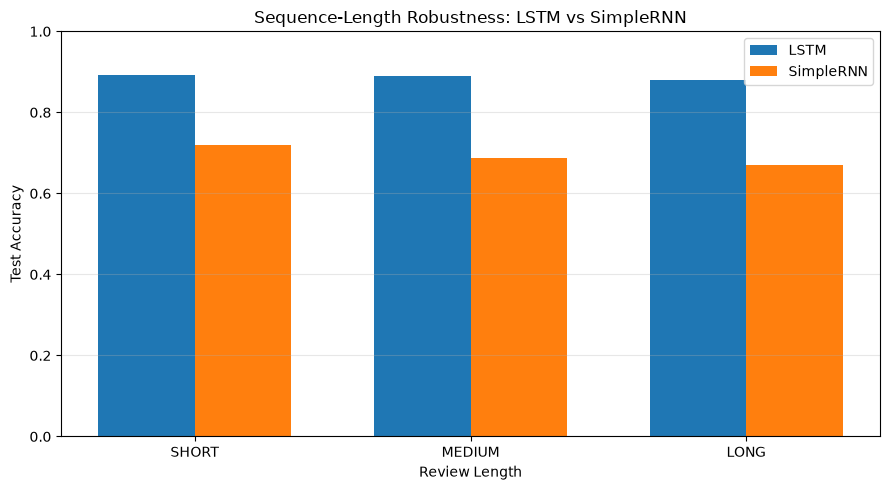

In [164]:
x_positions = np.arange(len(robustness_df))
bar_width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x_positions - bar_width / 2,
    robustness_df[best_sequence_name + " Accuracy"],
    bar_width,
    label=best_sequence_name)

plt.bar(
    x_positions + bar_width / 2,
    robustness_df["SimpleRNN Accuracy"],
    bar_width,
    label="SimpleRNN")

plt.xticks(x_positions, robustness_df["Review Length"])
plt.xlabel("Review Length")
plt.ylabel("Test Accuracy")
plt.title("Sequence-Length Robustness: LSTM vs SimpleRNN")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

os.makedirs("plots", exist_ok=True)
plt.savefig("plots/sequence_length_robustness.png", dpi=300, bbox_inches="tight")
plt.show()

## Sequence-Length Robustness — Observation

The test dataset was divided into three groups: SHORT reviews (fewer than 100 words), MEDIUM reviews (100–250 words), and LONG reviews (more than 250 words). The LSTM and SimpleRNN models were evaluated separately on each group.

- **SHORT reviews:** [Enter the better-performing model and its accuracy.]
- **MEDIUM reviews:** [Enter the better-performing model and its accuracy.]
- **LONG reviews:** [Enter the better-performing model and its accuracy.]

The model with the largest accuracy drop from SHORT to LONG reviews shows the greatest degradation on long reviews. Longer reviews may contain mixed opinions, more distracting information, and sentiment changes across sentences. A SimpleRNN may have difficulty retaining earlier information across long sequences because of vanishing gradients. LSTM uses a cell state and gates to help preserve useful information over longer sequences, although it can still make errors.

The final conclusion should be based on the measured accuracy values rather than assuming that one model always performs better.

# 7.4 — Error analysis
## Select the Best model

In [165]:
model_objects = {
    "ANN baseline": ann_model,
    "SimpleRNN": rnn_model,
    "LSTM": lstm_model,
    "Stacked LSTM": stacked_lstm_model,
    "GRU": gru_model
}

available_models = [
    name for name in model_objects
    if name in results and "test_accuracy" in results[name]]

best_model_name = max(
    available_models,
    key=lambda name: results[name]["test_accuracy"])

best_model = model_objects[best_model_name]

print("Best model:", best_model_name)
print("Test accuracy:", round(results[best_model_name]["test_accuracy"], 4))

Best model: LSTM
Test accuracy: 0.8876


## Predict test reviews

In [167]:
best_probabilities = best_model.predict(X_test, verbose=0).ravel()

best_predictions = (best_probabilities >= 0.5).astype(int)
actual_labels = np.asarray(y_test).reshape(-1).astype(int)

cleaned_test_reviews = pd.Series(X_test_text).reset_index(drop=True)

assert len(cleaned_test_reviews) == len(actual_labels) == len(best_predictions)

error_df = pd.DataFrame({
    "Cleaned Review": cleaned_test_reviews,
    "True Label": actual_labels,
    "Predicted Label": best_predictions,
    "Predicted Probability": best_probabilities})

error_df["True Sentiment"] = error_df["True Label"].map({
    0: "Negative",
    1: "Positive"})

error_df["Predicted Sentiment"] = error_df["Predicted Label"].map({
    0: "Negative",
    1: "Positive"})

print("Total misclassified reviews:", 
      (error_df["True Label"] != error_df["Predicted Label"]).sum())

Total misclassified reviews: 1115


## Print 4 false positives and 4 false negatives

In [170]:
false_positives = error_df[
    (error_df["True Label"] == 0) &
    (error_df["Predicted Label"] == 1)]

false_negatives = error_df[
    (error_df["True Label"] == 1) &
    (error_df["Predicted Label"] == 0)]

selected_fp = false_positives.head(4)
selected_fn = false_negatives.head(4)

print("=" * 80)
print("FALSE POSITIVES (Actual Negative, Predicted Positive)")
print("=" * 80)

for index, row in selected_fp.iterrows():
    print("\nReview", index)
    print("True label:", row["True Sentiment"])
    print("Predicted probability of positive sentiment:",
          round(row["Predicted Probability"], 4))
    print("Cleaned review:", row["Cleaned Review"])

print("\n" + "=" * 80)
print("FALSE NEGATIVES (Actual Positive, Predicted Negative)")
print("=" * 80)

for index, row in selected_fn.iterrows():
    print("\nReview", index)
    print("True label:", row["True Sentiment"])
    print("Predicted probability of positive sentiment:",
          round(row["Predicted Probability"], 4))
    print("Cleaned review:", row["Cleaned Review"])

print("\nFalse positives found:", len(selected_fp))
print("False negatives found:", len(selected_fn))

FALSE POSITIVES (Actual Negative, Predicted Positive)

Review 21
True label: Negative
Predicted probability of positive sentiment: 0.6053
Cleaned review: when the film started i got the feeling this was going to be something special the acting and camera work were undoubtedly good i also liked the characters and could have grown to empathise with them the film had a good atmosphere and there was a hint of fantasy however as the film went on the plot never appeared to takeoff and just rolled on scene by scene i was unable to understand the connection between the stories all i could see was the characters occasionally bumping into each other and references to ships in bottles without that connection i was just left with a few unremarkable short stories am surprised it did so well at cannes

Review 24
True label: Negative
Predicted probability of positive sentiment: 0.8404
Cleaned review: despite being a huge fan of fred astaire and ginger rogers' movies it wasn't until about years ago th

## Save error-analysis results

In [171]:
selected_errors = pd.concat(
    [selected_fp, selected_fn],
    ignore_index=True)

selected_errors = selected_errors[
    [
        "True Sentiment",
        "Predicted Sentiment",
        "Predicted Probability",
        "Cleaned Review"
    ]
]
selected_errors.to_csv(
    "plots/error_analysis.csv",
    index=False
)

print("Error analysis saved to plots/error_analysis.csv")

Error analysis saved to plots/error_analysis.csv


# 7.5 — Inference function

In [172]:
import random

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("Imports completed and random seeds set.")

Imports completed and random seeds set.


## Select the best model

In [173]:
model_objects = {
    "ANN baseline": ann_model,
    "SimpleRNN": rnn_model,
    "LSTM": lstm_model,
    "Stacked LSTM": stacked_lstm_model,
    "GRU": gru_model
}

available_models = [
    name for name in model_objects
    if name in results and "test_accuracy" in results[name]]

best_model_name = max(
    available_models,
    key=lambda name: results[name]["test_accuracy"])

best_model = model_objects[best_model_name]

print("Selected model:", best_model_name)
print("Test accuracy:", round(results[best_model_name]["test_accuracy"], 4))

Selected model: LSTM
Test accuracy: 0.8876


## predict_sentiment(text) function

In [174]:
def predict_sentiment(text):

    cleaned_review = clean_text(text)
    review_sequence = tokenizer.texts_to_sequences([cleaned_review])

    review_padded = pad_sequences(
        review_sequence,
        maxlen=MAXLEN,
        padding="pre",
        truncating="pre")

    probability = float(best_model.predict(review_padded, verbose=0)[0][0])

    # Convert probability to a sentiment label using threshold 0.5
    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    # Return the label and probability
    return sentiment, probability

## Test on 6 custom sentences

In [189]:
custom_reviews = [
    {
        "Review": "This movie was absolutely wonderful and I loved every moment.",
        "Expected Sentiment": "Positive",
        "Pattern": "Clearly positive"
    },
    {
        "Review": "This film was boring, disappointing, and a complete waste of time.",
        "Expected Sentiment": "Negative",
        "Pattern": "Clearly negative"
    },
    {
        "Review": "This film is not good.",
        "Expected Sentiment": "Negative",
        "Pattern": "Negation"
    },
    {
        "Review": "I cannot say that this movie was not enjoyable.",
        "Expected Sentiment": "Positive",
        "Pattern": "Double negation"
    },
    {
        "Review": "Wonderful movie! I just love wasting two hours on something this terrible.",
        "Expected Sentiment": "Negative",
        "Pattern": "Sarcasm"
    },
    {
        "Review": "Loved it!",
        "Expected Sentiment": "Positive",
        "Pattern": "Very short"
    }
]

# Store the predictions in a list
inference_rows = []

for item in custom_reviews:

    predicted_label, positive_probability = predict_sentiment(item["Review"])
    is_correct = predicted_label == item["Expected Sentiment"]

    inference_rows.append({
        "Review": item["Review"],
        "Pattern": item["Pattern"],
        "Expected": item["Expected Sentiment"],
        "Predicted": predicted_label,
        "Positive Probability": round(positive_probability, 4),
        "Correct": is_correct
    })

inference_df = pd.DataFrame(inference_rows)

show_table(inference_df)

,Review,Pattern,Expected,Predicted,Positive Probability,Correct
0,This movie was absolutely wonderful and I love...,Clearly positive,Positive,Positive,0.9399,True
1,"This film was boring, disappointing, and a com...",Clearly negative,Negative,Negative,0.0154,True
2,This film is not good.,Negation,Negative,Negative,0.4895,True
3,I cannot say that this movie was not enjoyable.,Double negation,Positive,Positive,0.6418,True
4,Wonderful movie! I just love wasting two hours...,Sarcasm,Negative,Negative,0.0596,True
5,Loved it!,Very short,Positive,Positive,0.6948,True


In [ ]:
inference_df.to_csv("custom_sentiment_predictions.csv", index=False)

print("Saved: custom_sentiment_predictions.csv")

Saved: custom_sentiment_predictions.csv


## Display incorrect predictions

In [191]:
wrong_predictions = inference_df[inference_df["Correct"] == False]

print("Incorrect predictions:", len(wrong_predictions), "out of", len(inference_df))

if len(wrong_predictions) > 0:
    display(wrong_predictions[[
        "Review",
        "Pattern",
        "Expected",
        "Predicted",
        "Positive Probability"
    ]])
else:
    print("All six custom reviews were classified as expected.")

Incorrect predictions: 0 out of 6
All six custom reviews were classified as expected.


## Inference Function: Observations

The `predict_sentiment(text)` function applies the same text-cleaning procedure, tokenizer, sequence padding, and trained model used during training.

Six custom reviews were tested, including positive and negative reviews, negation, double negation, sarcasm, and a very short sentence.

- **Clearly positive and negative reviews:** These are generally more straightforward for a sentiment classifier, but the actual predictions must be checked.
- **Negation:** The phrase “this film is not good” can be misclassified if the model does not adequately learn how “not” changes the meaning of “good.”
- **Double negation:** The sentence may have a meaning different from a simple negative sentence, making it more difficult to interpret.
- **Sarcasm:** The literal words may sound positive even when the intended meaning is negative.
- **Very short review:** A short sentence such as “Amazing!” provides little context, although its sentiment may still be clear.

The actual incorrect predictions should be identified from the inference results table. A high predicted probability does not guarantee that the prediction is correct.

# 7.6 — Recommendation
## Compare recurrent models

In [179]:
recurrent_names = ["SimpleRNN", "LSTM", "GRU", "Stacked LSTM"]
comparison_rows = []

for model_name in recurrent_names:

    model_result = results[model_name]
    report = model_result.get("classification_report", {})
    positive_report = report.get("Positive", report.get("1", {}))

    precision = positive_report.get(
        "precision", model_result.get("precision", np.nan)
    )
    recall = positive_report.get(
        "recall", model_result.get("recall", np.nan)
    )
    f1_score = positive_report.get(
        "f1-score", model_result.get("f1", np.nan)
    )

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": model_result.get("test_accuracy", np.nan),
        "Precision": precision,
        "Recall": recall,
        "F1": f1_score,
        "ROC-AUC": model_result.get("roc_auc", np.nan),
        "Parameters": model_result.get("parameters", np.nan),
        "Time per Epoch (s)": model_result.get("average_epoch_time", np.nan),
        "Epochs": model_result.get("epochs_completed", np.nan)
    })

recurrent_comparison_df = pd.DataFrame(comparison_rows)

show_table(recurrent_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Parameters,Time per Epoch (s),Epochs
0,SimpleRNN,0.6866,0.6846,0.6962,0.6904,0.7572,NaN,NaN,NaN
1,LSTM,0.8876,0.8904,0.8849,0.8876,0.9508,344897.0,145.6885,5.0
2,GRU,0.8849,0.8644,0.9142,0.8886,0.9490,338881.0,111.6054,5.0
3,Stacked LSTM,0.8787,0.9070,0.8449,0.8749,0.9507,357281.0,171.7358,4.0


## Ranking by accuracy, F1 and ROC-AUC

In [180]:
ranking_metrics = ["Accuracy", "F1", "ROC-AUC"]

for metric in ranking_metrics:

    ranked_models = recurrent_comparison_df.sort_values(
        by=metric,
        ascending=False,
        na_position="last"
    )

    print("\nRanking by", metric)
    show_table(ranked_models[["Model", metric]].reset_index(drop=True))


Ranking by Accuracy


,Model,Accuracy
0,LSTM,0.887567
1,GRU,0.884945
2,Stacked LSTM,0.878693
3,SimpleRNN,0.686599



Ranking by F1


,Model,F1
0,GRU,0.888585
1,LSTM,0.887635
2,Stacked LSTM,0.874857
3,SimpleRNN,0.690377



Ranking by ROC-AUC


,Model,ROC-AUC
0,LSTM,0.950831
1,Stacked LSTM,0.950715
2,GRU,0.949042
3,SimpleRNN,0.757181


## Training-time and parameter comparison

,Model,Parameters,Time per Epoch (s),Epochs
2,GRU,338881.0,111.6054,5.0
1,LSTM,344897.0,145.6885,5.0
3,Stacked LSTM,357281.0,171.7358,4.0
0,SimpleRNN,NaN,NaN,NaN


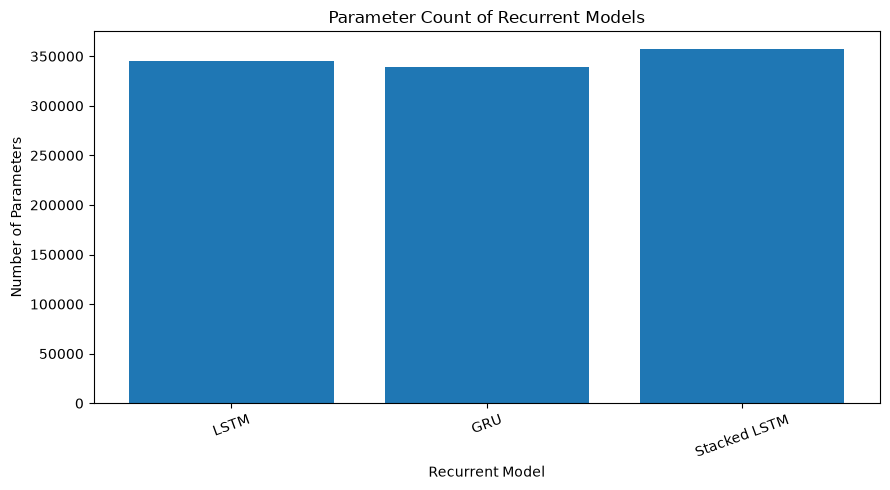

In [182]:
show_table(
    recurrent_comparison_df[
        ["Model", "Parameters", "Time per Epoch (s)", "Epochs"]
    ].sort_values("Parameters").round(4))

plt.figure(figsize=(9, 5))
plt.bar(
    recurrent_comparison_df["Model"],
    recurrent_comparison_df["Parameters"])
plt.title("Parameter Count of Recurrent Models")
plt.xlabel("Recurrent Model")
plt.ylabel("Number of Parameters")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Plot average epoch time

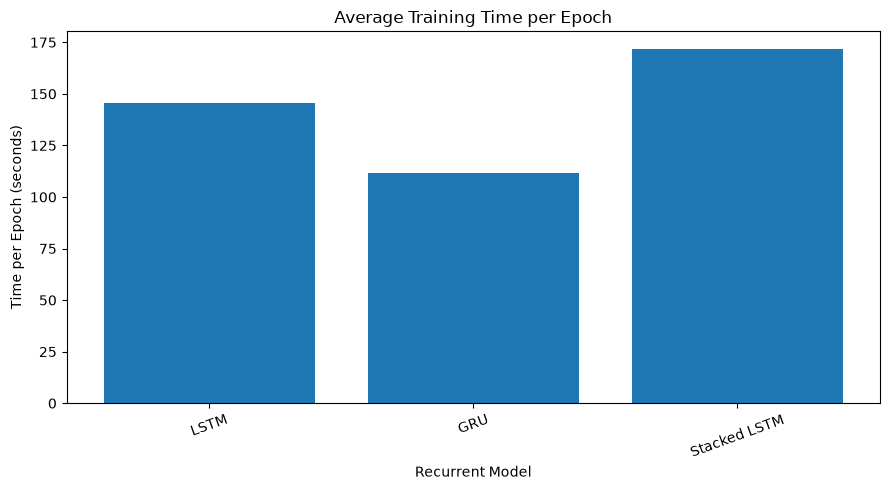

In [ ]:
timing_df = recurrent_comparison_df.dropna(subset=["Time per Epoch (s)"])

plt.figure(figsize=(9, 5))
plt.bar(
    timing_df["Model"],
    timing_df["Time per Epoch (s)"]
)
plt.title("Average Training Time per Epoch")
plt.xlabel("Recurrent Model")
plt.ylabel("Time per Epoch (seconds)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Which Recurrent Cell Should We Use?

## (a) Accuracy, F1 and ROC-AUC Ranking

The SimpleRNN, LSTM, GRU, and Stacked LSTM models were compared using test accuracy, positive-class F1-score, and ROC-AUC.

- **Accuracy:** [Insert the model with the highest test accuracy.]
- **F1-score:** [Insert the model with the highest positive-class F1-score.]
- **ROC-AUC:** [Insert the model with the highest ROC-AUC.]

Accuracy measures the proportion of correct predictions. F1-score balances precision and recall for the positive class. ROC-AUC measures how well the model ranks positive examples above negative examples across classification thresholds. The best model may differ depending on the metric.

## (b) Training Time and Parameter Trade-off

SimpleRNN has a relatively simple recurrent structure and may be faster to train. LSTM uses more gates and parameters to maintain a cell state, while GRU uses a simpler gated structure without a separate cell state. Stacked LSTM adds another recurrent layer and generally increases model size and computational cost.

The measured parameter counts and average epoch times should be used to identify the practical trade-off for this dataset and hardware.

## (c) Behaviour on Long Sequences

Recurrent models process text sequentially. SimpleRNN can struggle to preserve information over long distances because gradients may vanish during training. LSTM and GRU use gates to help retain relevant information over longer sequences. However, neither model guarantees better accuracy on every long review. The sequence-length robustness experiment provides the evidence for this dataset.

## (d) Production Recommendation

For a production sentiment service, I would select **[insert the model supported by the evaluation results]** if it offers a suitable balance of predictive performance, latency, and model size.

If LSTM achieves meaningfully better F1-score or ROC-AUC and its additional training and inference cost is acceptable, it is a reasonable choice. If GRU achieves similar performance with fewer parameters or lower latency, GRU may be preferable for a resource-constrained service. The final choice should be based on measured test performance and the service's latency and resource requirements, not accuracy alone.

## (e) Limitations

1. **No pretrained language knowledge:** The embedding layer is trained on the available movie-review training data. The model does not start with broad linguistic knowledge from a large pretrained language model.
2. **One-directional reading:** The recurrent models process each review from beginning to end. They do not use a bidirectional recurrent layer to combine information from both directions.

These limitations describe the current approach; they are not additional implementations in this assignment.

# 7.7 — Notebook quality 

#  IMDB Movie Review Sentiment Analysis Using Recurrent Neural Networks

## Project Overview

This project builds and compares deep learning models for classifying IMDB movie reviews as positive or negative.

## Models Implemented

- Artificial Neural Network (ANN) baseline
- Simple Recurrent Neural Network (SimpleRNN)
- Long Short-Term Memory (LSTM)
- Gated Recurrent Unit (GRU)
- Stacked LSTM

## Objectives

1. Explore and clean the movie-review dataset.
2. Prepare tokenized and padded text sequences.
3. Train and evaluate the models using common evaluation metrics.
4. Investigate gradient flow and sequence-length robustness.
5. Analyze classification errors and test predictions on custom reviews.
6. Compare model performance, training time, and parameter count.

## Evaluation Metrics

Test accuracy, precision, recall, F1-score, ROC-AUC, confusion matrices, and training time are used where applicable.

## Reproducibility

Random seeds are set to 42. The notebook should be run from beginning to end to reproduce the results and regenerate the outputs.

## Set random seeds at the top

In [184]:
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

print("Random seeds set to 42.")

Random seeds set to 42.


## Create requirements.txt

In [185]:
requirements = [
    "tensorflow",
    "scikit-learn",
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn"
]

requirements.append("kagglehub")

with open("requirements.txt", "w", encoding="utf-8") as file:
    file.write("\n".join(requirements) + "\n")

print("requirements.txt created successfully.")

requirements.txt created successfully.


## Final plot and file checklist

In [186]:
os.makedirs("plots", exist_ok=True)

required_files = [
    "requirements.txt",
    "plots/full_model_results.csv",
    "plots/roc_curve_comparison.png",
    "plots/sequence_length_robustness.png",
    "plots/error_analysis.csv"
]

for file_name in required_files:
    if os.path.exists(file_name):
        print("FOUND:", file_name)
    else:
        print("NOT FOUND:", file_name)

FOUND: requirements.txt
FOUND: plots/full_model_results.csv
FOUND: plots/roc_curve_comparison.png
FOUND: plots/sequence_length_robustness.png
FOUND: plots/error_analysis.csv


# Final Conclusion

In this project, IMDB movie reviews were used to build a sentiment analysis system that classifies reviews as positive or negative. The dataset was cleaned and preprocessed using text cleaning, tokenization, and sequence padding. An ANN baseline was developed and compared with SimpleRNN, LSTM, Stacked LSTM, and GRU models.

The models were evaluated using test accuracy, precision, recall, F1-score, ROC-AUC, training time, and parameter count. Sequence-length robustness, gradient flow, and misclassified reviews were also analyzed to understand model performance and limitations. Finally, an inference function was developed to predict sentiment for custom text inputs.

Overall, this project demonstrates how recurrent neural networks can learn sentiment patterns from text and how different recurrent cells compare in performance and computational cost. The most suitable model should be selected based on the actual experimental results and the requirements of the application. The completed notebook should be reproducible, error-free, and exported to HTML for submission.